# <font color='blue'>Projeto 1</font>
# <font color='blue'>Evolução do Ensino Superior Brasileiro</font>

In [1]:
# Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import warnings
warnings.filterwarnings('ignore')

In [2]:
# !pip install -q -U watermark

In [3]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Mauricio Vinhote" 

Author: Mauricio Vinhote



# Pergunta de negócio

> **Como a oferta e a demanda por ensino superior no Brasil evoluíram entre 2009 e 2024, e quais segmentos apresentaram as maiores mudanças?**

O objetivo é produzir um diagnóstico da evolução do sistema de ensino superior brasileiro.

## Objetivos específicos

Investigar:

- evolução do número de cursos;
- evolução do número de vagas;
- evolução dos ingressantes;
- evolução das matrículas;
- evolução dos concluintes;
- diferenças entre instituições públicas e privadas;
- diferenças entre ensino presencial e EAD;
- diferenças entre regiões e estados.

## Etapas

### 1. Definir a unidade de análise

Inicialmente, pode-se trabalhar com:

$$
\text{ano} \times \text{curso}
$$

ou realizar agregações como:

$$
\text{ano} \times \text{UF}.
$$

### 2. Selecionar as variáveis

Por exemplo:

    NU_ANO_CENSO
    QT_CURSO
    QT_VG_TOTAL
    QT_ING
    QT_MAT
    QT_CONC
    TP_CATEGORIA_ADMINISTRATIVA
    TP_MODALIDADE_ENSINO
    CO_UF

### 3. Realizar a limpeza dos dados

Verificar:

- tipos das variáveis;
- valores ausentes;
- duplicidades;
- consistência dos anos;
- categorias das variáveis qualitativas;
- valores extremos;
- consistência dos totais.

### 4. Agregar os dados

Por exemplo, para obter o total de matrículas por ano:

$$
M_t = \sum_i QT\_MAT_{i,t}.
$$

### 5. Criar indicadores

Taxa de crescimento:

$$
g_t =
\frac{X_t-X_{t-1}}
{X_{t-1}}
\times 100.
$$

Participação de determinado segmento:

$$
P_t =
\frac{X_t}
{X_{\text{total},t}}
\times 100.
$$

### 6. Produzir visualizações

Criar:

- gráficos de linhas;
- gráficos de barras;
- gráficos de área;
- gráficos de composição;
- mapas por UF.

### 7. Interpretar os resultados

Responder:

- O que mudou?
- Quando mudou?
- Onde mudou?
- Quais segmentos cresceram mais?
- Quais segmentos diminuíram?
- Houve mudanças estruturais?

## Competências desenvolvidas

- Pandas;
- agrupamento;
- agregação;
- análise exploratória;
- visualização;
- séries temporais básicas;
- criação de indicadores.

---


# Preparação da base de dados

Sobre a base de dados...

A base de dados Cadastro_Cursos reúne informações referentes aos cursos de graduação das instituições de educação superior, tendo como unidade de informação o curso. De acordo com o dicionário de dados, a base contém variáveis de identificação temporal, localização geográfica e informações relacionadas ao curso e à instituição de ensino superior, permitindo caracterizar onde os cursos são oferecidos e suas principais características.

A base também apresenta informações quantitativas sobre a oferta e o funcionamento dos cursos, incluindo quantidade de vagas, ingressantes, matrículas e concluintes , além de informações relacionadas a diferentes características dos estudantes, como apoio social, atividades extracurriculares e mobilidade acadêmica. O dicionário identifica essas variáveis como numéricas e apresenta a descrição de cada uma delas.

Dessa forma, o Cadastro_Cursos constitui uma fonte de dados adequada para analisar a oferta e a dinâmica dos cursos de graduação no ensino superior brasileiro, possibilitando a realização de análises temporais, regionais e institucionais , bem como a construção de indicadores relacionados à oferta de vagas, ingresso, matrícula e conclusão dos estudantes.

A base do Censo da Educação Superior é particularmente adequada para projetos de Ciência de Dados porque combina:

- dimensão temporal, de 2009 a 2024;
- informações sobre cursos;
- instituições;
- localização geográfica;
- ingressantes;
- matrículas;
- concluintes;
- vagas;
- modalidade de ensino;
- características demográficas dos estudantes;
- financiamento estudantil;
- ações afirmativas;
- mobilidade acadêmica.

Isso permite construir uma sequência de projetos que percorre praticamente todo o fluxo de um projeto de Ciência de Dados:

$$
\boxed{
\text{EDA}
\rightarrow
\text{Estatística}
\rightarrow
\text{Visualização}
\rightarrow
\text{Feature Engineering}
\rightarrow
\text{Machine Learning}
\rightarrow
\text{Séries Temporais}
\rightarrow
\text{Clustering}
\rightarrow
\text{Análise Espacial}
}
$$

---

O objetivo desta primeira tarefa é preparar um dataframe contendo os dados do censo de 2009 a 2024. Por enquanto, o que temos como dados é um dataframe com dados do censo para cada ano. 

Os dicionários a seguir contem a descrição das variáveis comuns a todos os datasets, cada um com dados do censo para um determinado ano entre 2009 e 2024.

In [ ]:
dicionario_cursos = {
    'CO_CINE_AREA_DETALHADA': 'Código de identificação da área detalhada, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'CO_CINE_AREA_ESPECIFICA': 'Código de identificação da área específica, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'CO_CINE_AREA_GERAL': 'Código de identificação da área geral, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'CO_IES': 'Código da Instituição',
    'CO_MUNICIPIO': 'Código do IBGE do Município do local de oferta do curso',
    'CO_REGIAO': 'Código da região geográfica do local de oferta do curso',
    'CO_UF': 'Código do IBGE da Unidade da Federação do local de oferta do curso',
    'IN_CAPITAL': 'Informa se o local de oferta do curso está localizado na capital da Unidade da Federação',
    'NO_CINE_AREA_DETALHADA': 'Nome da área detalhada, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_CINE_AREA_ESPECIFICA': 'Nome da área específica, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_CINE_AREA_GERAL': 'Nome da área geral, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_CINE_ROTULO': 'Nome do curso, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_MUNICIPIO': 'Nome do Município do local de oferta do curso',
    'NO_REGIAO': 'Nome da região geográfica do local de oferta do curso',
    'NO_UF': 'Nome da Unidade da Federação do local de oferta do curso',
    'NU_ANO_CENSO': 'Ano de referência do Censo da Educação Superior',
    'QT_ALUNO_DEFICIENTE': 'Quantidade de alunos com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_APOIO_SOCIAL': 'Quantidade de alunos que recebem algum tipo de apoio social',
    'QT_ATIV_EXTRACURRICULAR': 'Quantidade de alunos que participam de algum tipo de atividade extracurricular',
    'QT_CONC': 'Quantidade de concluintes',
    'QT_CONC_0_17': 'Quantidade de concluintes - Até 17 anos de idade',
    'QT_CONC_18_24': 'Quantidade de concluintes - De 18 a 24 anos de idade',
    'QT_CONC_25_29': 'Quantidade de concluintes - De 25 a 29 anos de idade',
    'QT_CONC_30_34': 'Quantidade de concluintes - De 30 a 34 anos de idade',
    'QT_CONC_35_39': 'Quantidade de concluintes - De 35 a 39 anos de idade',
    'QT_CONC_40_49': 'Quantidade de concluintes - De 40 a 49 anos de idade',
    'QT_CONC_50_59': 'Quantidade de concluintes - De 50 a 59 anos de idade',
    'QT_CONC_60_MAIS': 'Quantidade de concluintes - De 60 a 59 anos de idade',
    'QT_CONC_AMARELA': 'Quantidade de concluintes - Cor/Raça amarela',
    'QT_CONC_APOIO_SOCIAL': 'Quantidade de concluintes que recebem algum tipo de apoio social',
    'QT_CONC_ATIV_EXTRACURRICULAR': 'Quantidade de concluintes que participam de algum tipo de atividade extracurricular',
    'QT_CONC_BRANCA': 'Quantidade de concluintes - Cor/Raça branca',
    'QT_CONC_CORND': 'Quantidade de concluintes - Cor/Raça não dispõe da informação ou não declarada',
    'QT_CONC_DEFICIENTE': 'Quantidade de concluintes com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_CONC_DIURNO': 'Quantidade de concluintes no turno diurno',
    'QT_CONC_FEM': 'Quantidade de concluintes do sexo feminino',
    'QT_CONC_FIES': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável - FIES',
    'QT_CONC_FINANC': 'Quantidade de concluintes que utilizam financiamento estudantil',
    'QT_CONC_FINANC_NREEMB': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável',
    'QT_CONC_FINANC_NREEMB_OUTROS': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_CONC_FINANC_REEMB': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável',
    'QT_CONC_FINANC_REEMB_OUTROS': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_CONC_INDIGENA': 'Quantidade de concluintes - Cor/Raça indígena',
    'QT_CONC_MASC': 'Quantidade de concluintes do sexo masculino',
    'QT_CONC_MOB_ACADEMICA': 'Quantidade de concluintes que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_CONC_NACBRAS': 'Quantidade de concluintes - nacionalidade brasileira ou brasileira - nascido no exterior ou naturalizado',
    'QT_CONC_NACESTRANG': 'Quantidade de concluintes - nacionalidade estrangeira',
    'QT_CONC_NOTURNO': 'Quantidade de concluintes no turno noturno',
    'QT_CONC_NRPFIES': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - administrado pela instituição',
    'QT_CONC_PARDA': 'Quantidade de concluintes - Cor/Raça parda',
    'QT_CONC_PARFOR': 'Quantidade de concluintes que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_CONC_PRETA': 'Quantidade de concluintes - Cor/Raça preta',
    'QT_CONC_PROCESCPRIVADA': 'Quantidade de concluintes que terminaram o ensino médio em escolas privadas',
    'QT_CONC_PROCESCPUBLICA': 'Quantidade de concluintes que terminaram o ensino médio em escolas públicas',
    'QT_CONC_PROCNAOINFORMADA': 'Quantidade de concluintes que não informaram o tipo de escola que terminaram o ensino médio',
    'QT_CONC_PROUNII': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - PROUNI Integral',
    'QT_CONC_PROUNIP': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - PROUNI Parcial',
    'QT_CONC_RESERVA_VAGA': 'Quantidade de concluintes que ingressaram por meio de política de ação afirmativa ou por programa diferenciado de destinação de vagas',
    'QT_CONC_RPFIES': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável - administrado pela instituição',
    'QT_CONC_RVOUTROS': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - outros tipos',
    'QT_CONC_RVPDEF': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - pessoas com deficiência',
    'QT_CONC_RVREDEPUBLICA': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - escola pública',
    'QT_CONC_RVSOCIAL_RF': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - cunho social/renda familiar',
    'QT_CURSO': 'Quantidade de cursos',
    'QT_ING': 'Quantidade de ingressantes',
    'QT_ING_0_17': 'Quantidade de ingressantes - Até 17 anos de idade',
    'QT_ING_18_24': 'Quantidade de ingressantes - De 18 a 24 anos de idade',
    'QT_ING_25_29': 'Quantidade de ingressantes - De 25 a 29 anos de idade',
    'QT_ING_30_34': 'Quantidade de ingressantes - De 30 a 34 anos de idade',
    'QT_ING_35_39': 'Quantidade de ingressantes - De 35 a 39 anos de idade',
    'QT_ING_40_49': 'Quantidade de ingressantes - De 40 a 49 anos de idade',
    'QT_ING_50_59': 'Quantidade de ingressantes - De 50 a 59 anos de idade',
    'QT_ING_60_MAIS': 'Quantidade de ingressantes - De 60 anos ou mais',
    'QT_ING_AMARELA': 'Quantidade de ingressantes - Cor/Raça amarela',
    'QT_ING_APOIO_SOCIAL': 'Quantidade de ingressantes que recebem algum tipo de apoio social',
    'QT_ING_ATIV_EXTRACURRICULAR': 'Quantidade de ingressantes que participam de algum tipo de atividade extracurricular',
    'QT_ING_AVALIACAO_SERIADA': 'Quantidade de ingressantes por avaliação seriada',
    'QT_ING_BRANCA': 'Quantidade de ingressantes - Cor/Raça branca',
    'QT_ING_CORND': 'Quantidade de ingressantes - Cor/Raça não dispõe da informação ou não declarada',
    'QT_ING_DEFICIENTE': 'Quantidade de ingressantes com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_ING_DIURNO': 'Quantidade de ingressantes no turno diurno',
    'QT_ING_EGR': 'Quantidade de ingressantes por outras formas de ingresso',
    'QT_ING_ENEM': 'Quantidade de ingressantes pelo ENEM',
    'QT_ING_FEM': 'Quantidade de ingressantes do sexo feminino',
    'QT_ING_FIES': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável - FIES',
    'QT_ING_FINANC': 'Quantidade de ingressantes que utilizam financiamento estudantil',
    'QT_ING_FINANC_NREEMB': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável',
    'QT_ING_FINANC_NREEMB_OUTROS': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_ING_FINANC_REEMB': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável',
    'QT_ING_FINANC_REEMB_OUTROS': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_ING_INDIGENA': 'Quantidade de ingressantes - Cor/Raça indígena',
    'QT_ING_MASC': 'Quantidade de ingressantes do sexo masculino',
    'QT_ING_MOB_ACADEMICA': 'Quantidade de ingressantes que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_ING_NACBRAS': 'Quantidade de ingressantes - nacionalidade brasileira ou brasileira - nascido no exterior ou naturalizado',
    'QT_ING_NACESTRANG': 'Quantidade de ingressantes - nacionalidade estrangeira',
    'QT_ING_NOTURNO': 'Quantidade de ingressantes no turno noturno',
    'QT_ING_NRPFIES': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - administrado pela instituição',
    'QT_ING_OUTRA_FORMA': 'Quantidade de ingressantes por outras formas de ingresso',
    'QT_ING_OUTRO_TIPO_SELECAO': 'Quantidade de ingressantes em outro tipo de seleção',
    'QT_ING_PARDA': 'Quantidade de ingressantes - Cor/Raça parda',
    'QT_ING_PARFOR': 'Quantidade de ingressantes que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_ING_PRETA': 'Quantidade de ingressantes - Cor/Raça preta',
    'QT_ING_PROCESCPRIVADA': 'Quantidade de ingressantes que terminaram o ensino médio em escolas privadas',
    'QT_ING_PROCESCPUBLICA': 'Quantidade de ingressantes que terminaram o ensino médio em escolas públicas',
    'QT_ING_PROCNAOINFORMADA': 'Quantidade de ingressantes que não informaram o tipo de escola que terminaram o ensino médio',
    'QT_ING_PROC_SELETIVO': 'Quantidade de ingressantes nos processos seletivos',
    'QT_ING_PROUNII': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - PROUNI Integral',
    'QT_ING_PROUNIP': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - PROUNI Parcial',
    'QT_ING_RESERVA_VAGA': 'Quantidade de ingressantes que ingressaram por meio de política de ação afirmativa ou por programa diferenciado de destinação de vagas',
    'QT_ING_RPFIES': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável - administrado pela instituição',
    'QT_ING_RVETNICO': 'Quantidade de ingressantes que participam do programa de reserva de vagas - cunho étnico',
    'QT_ING_RVOUTROS': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - outros tipos',
    'QT_ING_RVPDEF': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - pessoas com deficiência',
    'QT_ING_RVREDEPUBLICA': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - escola pública',
    'QT_ING_RVSOCIAL_RF': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - cunho social/renda familiar',
    'QT_ING_SELECAO_SIMPLIFICA': 'Quantidade de ingressantes por meio de seleção simplificada',
    'QT_ING_VESTIBULAR': 'Quantidade de ingressantes por vestibular',
    'QT_ING_VG_NOVA': 'Quantidade de ingressantes em vagas novas',
    'QT_ING_VG_PROG_ESPECIAL': 'Quantidade de ingressantes por meio de vagas para programas especiais',
    'QT_ING_VG_REMANESC': 'Quantidade de ingressantes por meio de vagas remanescentes',
    'QT_INSCRITO_TOTAL': 'Quantidade total de inscritos',
    'QT_INSCRITO_TOTAL_DIURNO': 'Quantidade total de inscritos no turno diurno',
    'QT_INSCRITO_TOTAL_EAD': 'Quantidade total de inscritos no curso a distância',
    'QT_INSCRITO_TOTAL_NOTURNO': 'Quantidade total de inscritos no turno noturno',
    'QT_INSC_PROC_SELETIVO': 'Quantidade de inscritos nos processos seletivos',
    'QT_INSC_VG_NOVA': 'Quantidade de inscritos no processo seletivo de vagas novas',
    'QT_INSC_VG_PROG_ESPECIAL': 'Quantidade de inscritos no processo seletivo de vagas oferecidas para programas especiais',
    'QT_INSC_VG_REMANESC': 'Quantidade de inscritos no processo seletivo de vagas remanescentes',
    'QT_MAT': 'Quantidade de matrículas',
    'QT_MAT_0_17': 'Quantidade de matrículas - Até 17 anos de idade',
    'QT_MAT_18_24': 'Quantidade de matrículas - De 18 a 24 anos de idade',
    'QT_MAT_25_29': 'Quantidade de matrículas - De 25 a 29 anos de idade',
    'QT_MAT_30_34': 'Quantidade de matrículas - De 30 a 34 anos de idade',
    'QT_MAT_35_39': 'Quantidade de matrículas - De 35 a 39 anos de idade',
    'QT_MAT_40_49': 'Quantidade de matrículas - De 40 a 49 anos de idade',
    'QT_MAT_50_59': 'Quantidade de matrículas - De 50 a 59 anos de idade',
    'QT_MAT_60_MAIS': 'Quantidade de matrículas - De 60 ou mais anos de idade',
    'QT_MAT_AMARELA': 'Quantidade de matrículas - Cor/Raça amarela',
    'QT_MAT_APOIO_SOCIAL': 'Quantidade de matrículas de alunos que recebem algum tipo de apoio social',
    'QT_MAT_ATIV_EXTRACURRICULAR': 'Quantidade de matrículas de alunos que participam de algum tipo de atividade extracurricular',
    'QT_MAT_BRANCA': 'Quantidade de matrículas - Cor/Raça branca',
    'QT_MAT_CORND': 'Quantidade de matrículas - Cor/Raça não dispõe da informação ou não declarada',
    'QT_MAT_DEFICIENTE': 'Quantidade de matrículas - alunos com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_MAT_DIURNO': 'Quantidade de matrículas - turno diurno',
    'QT_MAT_FEM': 'Quantidade de matrículas do sexo feminino',
    'QT_MAT_FIES': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável - FIES',
    'QT_MAT_FINANC': 'Quantidade de matrículas que utilizam financiamento estudantil',
    'QT_MAT_FINANC_NREEMB': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável',
    'QT_MAT_FINANC_NREEMB_OUTROS': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_MAT_FINANC_REEMB': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável',
    'QT_MAT_FINANC_REEMB_OUTROS': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_MAT_INDIGENA': 'Quantidade de matrículas - Cor/Raça indígena',
    'QT_MAT_MASC': 'Quantidade de matrículas do sexo masculino',
    'QT_MAT_MOB_ACADEMICA': 'Quantidade de alunos regularmente matriculados que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_MAT_NACBRAS': 'Quantidade de matrículas - nacionalidade brasileira ou brasileira - nascido no exterior ou naturalizado',
    'QT_MAT_NACESTRANG': 'Quantidade de matrículas - nacionalidade estrangeira',
    'QT_MAT_NOTURNO': 'Quantidade de matrículas - turno noturno',
    'QT_MAT_NRPFIES': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - administrado pela instituição',
    'QT_MAT_PARDA': 'Quantidade de matrículas - Cor/Raça parda',
    'QT_MAT_PARFOR': 'Quantidade de matrículas de alunos que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_MAT_PRETA': 'Quantidade de matrículas - Cor/Raça preta',
    'QT_MAT_PROCESCPRIVADA': 'Quantidade de matrículas de alunos que terminaram o ensino médio em escolas privadas',
    'QT_MAT_PROCESCPUBLICA': 'Quantidade de matrículas de alunos que terminaram o ensino médio em escolas públicas',
    'QT_MAT_PROCNAOINFORMADA': 'Quantidade de matrículas de alunos que não informaram o tipo de escola que terminaram o ensino médio',
    'QT_MAT_PROUNII': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - PROUNI Integral',
    'QT_MAT_PROUNIP': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - PROUNI Parcial',
    'QT_MAT_RESERVA_VAGA': 'Quantidade de matrículas que ingressaram por meio de política de ação afirmativa ou por programa diferenciado de destinação de vagas',
    'QT_MAT_RPFIES': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável - administrado pela instituição',
    'QT_MAT_RVETNICO': 'Quantidade de matrículas que participam do programa de reserva de vagas - cunho étnico',
    'QT_MAT_RVOUTROS': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - outros tipos',
    'QT_MAT_RVPDEF': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - pessoas com deficiência',
    'QT_MAT_RVREDEPUBLICA': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - escola pública',
    'QT_MAT_RVSOCIAL_RF': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - cunho social/renda familiar',

    'QT_MOB_ACADEMICA': 'Quantidade de alunos que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_PARFOR': 'Quantidade de alunos que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_SIT_DESVINCULADO': 'Quantidade de alunos com situação de vínculo no curso - aluno desvinculado do curso',
    'QT_SIT_FALECIDO': 'Quantidade de alunos com situação de vínculo no curso - aluno falecido',
    'QT_SIT_TRANCADA': 'Quantidade de alunos com situação de vínculo no curso - matrícula trancada',
    'QT_SIT_TRANSFERIDO': 'Quantidade de alunos com situação de vínculo no curso - aluno transferido para outro curso da mesma IES',

    'QT_VG_NOVA': 'Quantidade de vagas novas oferecidas',
    'QT_VG_PROC_SELETIVO': 'Quantidade de vagas nos processos seletivos',
    'QT_VG_PROG_ESPECIAL': 'Quantidade de vagas oferecidas para programas especiais',
    'QT_VG_REMANESC': 'Quantidade de vagas remanescentes',
    'QT_VG_TOTAL': 'Quantidade total de vagas oferecidas',
    'QT_VG_TOTAL_DIURNO': 'Quantidade total de vagas oferecidas no turno diurno',
    'QT_VG_TOTAL_EAD': 'Quantidade total de vagas oferecidas no curso a distância',
    'QT_VG_TOTAL_NOTURNO': 'Quantidade total de vagas oferecidas no turno noturno',

    'SG_UF': 'Sigla da Unidade da Federação do local de oferta do curso',
    'TP_CATEGORIA_ADMINISTRATIVA': 'Tipo de Categoria Administrativa da IES',
    'TP_GRAU_ACADEMICO': 'Tipo do grau acadêmico conferido ao aluno pela conclusão dos requisitos exigidos pelo curso',
    'TP_MODALIDADE_ENSINO': 'Tipo de modalidade de ensino do curso',
    'TP_NIVEL_ACADEMICO': 'Tipo de nível acadêmico do curso',
    'TP_ORGANIZACAO_ACADEMICA': 'Tipo de Organização Acadêmica da IES',
    'TP_REDE': 'Rede de Ensino'
}


In [ ]:
variaveis_cursos = [
    'CO_CINE_AREA_DETALHADA',
    'CO_CINE_AREA_ESPECIFICA',
    'CO_CINE_AREA_GERAL',
    'CO_IES',
    'CO_MUNICIPIO',
    'CO_REGIAO',
    'CO_UF',
    'IN_CAPITAL',
    'NO_CINE_AREA_DETALHADA',
    'NO_CINE_AREA_ESPECIFICA',
    'NO_CINE_AREA_GERAL',
    'NO_CINE_ROTULO',
    'NO_MUNICIPIO',
    'NO_REGIAO',
    'NO_UF',
    'NU_ANO_CENSO',
    'QT_ALUNO_DEFICIENTE',
    'QT_APOIO_SOCIAL',
    'QT_ATIV_EXTRACURRICULAR',
    'QT_CONC',
    'QT_CONC_0_17',
    'QT_CONC_18_24',
    'QT_CONC_25_29',
    'QT_CONC_30_34',
    'QT_CONC_35_39',
    'QT_CONC_40_49',
    'QT_CONC_50_59',
    'QT_CONC_60_MAIS',
    'QT_CONC_AMARELA',
    'QT_CONC_APOIO_SOCIAL',
    'QT_CONC_ATIV_EXTRACURRICULAR',
    'QT_CONC_BRANCA',
    'QT_CONC_CORND',
    'QT_CONC_DEFICIENTE',
    'QT_CONC_DIURNO',
    'QT_CONC_FEM',
    'QT_CONC_FIES',
    'QT_CONC_FINANC',
    'QT_CONC_FINANC_NREEMB',
    'QT_CONC_FINANC_NREEMB_OUTROS',
    'QT_CONC_FINANC_REEMB',
    'QT_CONC_FINANC_REEMB_OUTROS',
    'QT_CONC_INDIGENA',
    'QT_CONC_MASC',
    'QT_CONC_MOB_ACADEMICA',
    'QT_CONC_NACBRAS',
    'QT_CONC_NACESTRANG',
    'QT_CONC_NOTURNO',
    'QT_CONC_NRPFIES',
    'QT_CONC_PARDA',
    'QT_CONC_PARFOR',
    'QT_CONC_PRETA',
    'QT_CONC_PROCESCPRIVADA',
    'QT_CONC_PROCESCPUBLICA',
    'QT_CONC_PROCNAOINFORMADA',
    'QT_CONC_PROUNII',
    'QT_CONC_PROUNIP',
    'QT_CONC_RESERVA_VAGA',
    'QT_CONC_RPFIES',
    'QT_CONC_RVOUTROS',
    'QT_CONC_RVPDEF',
    'QT_CONC_RVREDEPUBLICA',
    'QT_CONC_RVSOCIAL_RF',
    'QT_CURSO',
    'QT_ING',
    'QT_ING_0_17',
    'QT_ING_18_24',
    'QT_ING_25_29',
    'QT_ING_30_34',
    'QT_ING_35_39',
    'QT_ING_40_49',
    'QT_ING_50_59',
    'QT_ING_60_MAIS',
    'QT_ING_AMARELA',
    'QT_ING_APOIO_SOCIAL',
    'QT_ING_ATIV_EXTRACURRICULAR',
    'QT_ING_AVALIACAO_SERIADA',
    'QT_ING_BRANCA',
    'QT_ING_CORND',
    'QT_ING_DEFICIENTE',
    'QT_ING_DIURNO',
    'QT_ING_EGR',
    'QT_ING_ENEM',
    'QT_ING_FEM',
    'QT_ING_FIES',
    'QT_ING_FINANC',
    'QT_ING_FINANC_NREEMB',
    'QT_ING_FINANC_NREEMB_OUTROS',
    'QT_ING_FINANC_REEMB',
    'QT_ING_FINANC_REEMB_OUTROS',
    'QT_ING_INDIGENA',
    'QT_ING_MASC',
    'QT_ING_MOB_ACADEMICA',
    'QT_ING_NACBRAS',
    'QT_ING_NACESTRANG',
    'QT_ING_NOTURNO',
    'QT_ING_NRPFIES',
    'QT_ING_OUTRA_FORMA',
    'QT_ING_OUTRO_TIPO_SELECAO',
    'QT_ING_PARDA',
    'QT_ING_PARFOR',
    'QT_ING_PRETA',
    'QT_ING_PROCESCPRIVADA',
    'QT_ING_PROCESCPUBLICA',
    'QT_ING_PROCNAOINFORMADA',
    'QT_ING_PROC_SELETIVO',
    'QT_ING_PROUNII',
    'QT_ING_PROUNIP',
    'QT_ING_RESERVA_VAGA',
    'QT_ING_RPFIES',
    'QT_ING_RVOUTROS',
    'QT_ING_RVPDEF',
    'QT_ING_RVREDEPUBLICA',
    'QT_ING_RVSOCIAL_RF',
    'QT_ING_SELECAO_SIMPLIFICA',
    'QT_ING_VESTIBULAR',
    'QT_ING_VG_NOVA',
    'QT_ING_VG_PROG_ESPECIAL',
    'QT_ING_VG_REMANESC',
    'QT_INSCRITO_TOTAL',
    'QT_INSCRITO_TOTAL_DIURNO',
    'QT_INSCRITO_TOTAL_EAD',
    'QT_INSCRITO_TOTAL_NOTURNO',
    'QT_INSC_PROC_SELETIVO',
    'QT_INSC_VG_NOVA',
    'QT_INSC_VG_PROG_ESPECIAL',
    'QT_INSC_VG_REMANESC',
    'QT_MAT',
    'QT_MAT_0_17',
    'QT_MAT_18_24',
    'QT_MAT_25_29',
    'QT_MAT_30_34',
    'QT_MAT_35_39',
    'QT_MAT_40_49',
    'QT_MAT_50_59',
    'QT_MAT_60_MAIS',
    'QT_MAT_AMARELA',
    'QT_MAT_APOIO_SOCIAL',
    'QT_MAT_ATIV_EXTRACURRICULAR',
    'QT_MAT_BRANCA',
    'QT_MAT_CORND',
    'QT_MAT_DEFICIENTE',
    'QT_MAT_DIURNO',
    'QT_MAT_FEM',
    'QT_MAT_FIES',
    'QT_MAT_FINANC',
    'QT_MAT_FINANC_NREEMB',
    'QT_MAT_FINANC_NREEMB_OUTROS',
    'QT_MAT_FINANC_REEMB',
    'QT_MAT_FINANC_REEMB_OUTROS',
    'QT_MAT_INDIGENA',
    'QT_MAT_MASC',
    'QT_MAT_MOB_ACADEMICA',
    'QT_MAT_NACBRAS',
    'QT_MAT_NACESTRANG',
    'QT_MAT_NOTURNO',
    'QT_MAT_NRPFIES',
    'QT_MAT_PARDA',
    'QT_MAT_PARFOR',
    'QT_MAT_PRETA',
    'QT_MAT_PROCESCPRIVADA',
    'QT_MAT_PROCESCPUBLICA',
    'QT_MAT_PROCNAOINFORMADA',
    'QT_MAT_PROUNII',
    'QT_MAT_PROUNIP',
    'QT_MAT_RESERVA_VAGA',
    'QT_MAT_RPFIES',
    'QT_MAT_RVOUTROS',
    'QT_MAT_RVPDEF',
    'QT_MAT_RVREDEPUBLICA',
    'QT_MAT_RVSOCIAL_RF',
    'QT_MOB_ACADEMICA',
    'QT_PARFOR',
    'QT_SIT_DESVINCULADO',
    'QT_SIT_FALECIDO',
    'QT_SIT_TRANCADA',
    'QT_SIT_TRANSFERIDO',
    'QT_VG_NOVA',
    'QT_VG_PROC_SELETIVO',
    'QT_VG_PROG_ESPECIAL',
    'QT_VG_REMANESC',
    'QT_VG_TOTAL',
    'QT_VG_TOTAL_DIURNO',
    'QT_VG_TOTAL_EAD',
    'QT_VG_TOTAL_NOTURNO',
    'SG_UF',
    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_GRAU_ACADEMICO',
    'TP_MODALIDADE_ENSINO',
    'TP_NIVEL_ACADEMICO',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_REDE'
]

Abrimos todos os datasets.

In [ ]:
df_cursos_2009 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2009.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2010 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2010.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2011 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2011.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2012 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2012.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2013 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2013.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2014 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2014.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2015 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2015.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2016 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2016.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2017 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2017.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2018 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2018.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2019 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2019.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2020 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2020.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2021 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2021.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2022 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2022.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2023 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2023.CSV",
    sep=";",
    encoding="latin1"
)

df_cursos_2024 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\CURSOS\MICRODADOS_CADASTRO_CURSOS_2024.CSV",
    sep=";",
    encoding="latin1"
)

Após a abertura dos datasets, fazemos cópias de cada um a fim de que possamos fazer o processamento adequado sem alterar os datasets originais.

In [ ]:
cursos_2009_copia = df_cursos_2009.copy()
cursos_2010_copia = df_cursos_2010.copy()
cursos_2011_copia = df_cursos_2011.copy()
cursos_2012_copia = df_cursos_2012.copy()
cursos_2013_copia = df_cursos_2013.copy()
cursos_2014_copia = df_cursos_2014.copy()
cursos_2015_copia = df_cursos_2015.copy()
cursos_2016_copia = df_cursos_2016.copy()
cursos_2017_copia = df_cursos_2017.copy()
cursos_2018_copia = df_cursos_2018.copy()
cursos_2019_copia = df_cursos_2019.copy()
cursos_2020_copia = df_cursos_2020.copy()
cursos_2021_copia = df_cursos_2021.copy()
cursos_2022_copia = df_cursos_2022.copy()
cursos_2023_copia = df_cursos_2023.copy()
cursos_2024_copia = df_cursos_2024.copy()

Em cada dataset, introduzimos a variável ANO, que recebe como valor o número que indica o ano ao qual corresponde os dados do respectivo dataset.

In [ ]:
cursos_2009_copia.insert(0,"ANO",2009)
cursos_2010_copia.insert(0,"ANO",2010)
cursos_2011_copia.insert(0,"ANO",2011)
cursos_2012_copia.insert(0,"ANO",2012) 
cursos_2013_copia.insert(0,"ANO",2013) 
cursos_2014_copia.insert(0,"ANO",2014) 
cursos_2015_copia.insert(0,"ANO",2015) 
cursos_2016_copia.insert(0,"ANO",2016) 
cursos_2017_copia.insert(0,"ANO",2017) 
cursos_2018_copia.insert(0,"ANO",2018) 
cursos_2019_copia.insert(0,"ANO",2019) 
cursos_2020_copia.insert(0,"ANO",2020) 
cursos_2021_copia.insert(0,"ANO",2021) 
cursos_2022_copia.insert(0,"ANO",2022) 
cursos_2023_copia.insert(0,"ANO",2023) 
cursos_2024_copia.insert(0,"ANO",2024) 

Salvamos os dataframes cópia.

In [ ]:
cursos_2009_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2009.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2010_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2010.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2011_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2011.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2012_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2012.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2013_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2013.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2014_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2014.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2015_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2015.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2016_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2016.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2017_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2017.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2018_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2018.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2019_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2019.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2020_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2020.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2021_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2021.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2022_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2022.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2023_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2023.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

cursos_2024_copia.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2024.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

Abrimos os dataframes cópia.

In [ ]:
cursos_2009_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2009.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2010_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2010.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

In [ ]:
cursos_2011_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2011.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2012_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2012.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

In [ ]:
cursos_2013_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2013.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2014_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2014.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2015_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2015.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)


In [ ]:
cursos_2016_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2016.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2017_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2017.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2018_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2018.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2019_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2019.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2020_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2020.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2021_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2021.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2022_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2022.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2023_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2023.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

cursos_2024_copia = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2024.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

Agora concatenamos os dataframes verticalmente. Assim obtemos um único dataframe que contém dados do censo da educação superior de 2009 a 2024.

In [ ]:
df_cursos = pd.concat([
    cursos_2009_copia,
    cursos_2010_copia,
    cursos_2011_copia,
    cursos_2012_copia,
    cursos_2013_copia,
    cursos_2014_copia,
    cursos_2015_copia,
    cursos_2016_copia,
    cursos_2017_copia,
    cursos_2018_copia,
    cursos_2019_copia,
    cursos_2020_copia,
    cursos_2021_copia,
    cursos_2022_copia,
    cursos_2023_copia,
    cursos_2024_copia
], ignore_index=True)

Salvamos o dataframe principal.

In [ ]:
df_cursos.to_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2009_2024.csv",
    sep=';',
    index=False,
    encoding="latin1"
)

In [ ]:
df_cursos['NU_ANO_CENSO'].unique()

Agora liberamos espaço na mémória.

In [ ]:
del df_cursos

gc.collect()

In [ ]:
del cursos_2009_copia
del cursos_2010_copia
del cursos_2011_copia
del cursos_2012_copia
del cursos_2013_copia
del cursos_2014_copia
del cursos_2015_copia
del cursos_2016_copia
del cursos_2017_copia
del cursos_2018_copia
del cursos_2019_copia
del cursos_2020_copia
del cursos_2021_copia
del cursos_2022_copia
del cursos_2023_copia
del cursos_2024_copia


gc.collect()

# Execução do Projeto 1

## 1. Seleção de variáveis

Iniciamos com uma lista que agrupa todas as variáveis que iremos usar neste projeto.

In [4]:
variaveis_projeto_1 = [

    # ============================================================
    # 1. IDENTIFICAÇÃO TEMPORAL E LOCALIZAÇÃO
    # ============================================================

    'NU_ANO_CENSO',
    'NO_REGIAO',
    'NO_UF',


    # ============================================================
    # 2. CARACTERÍSTICAS INSTITUCIONAIS E DO CURSO
    # ============================================================

    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_REDE',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_MODALIDADE_ENSINO',

    'QT_CURSO',


    # ============================================================
    # 3. VAGAS
    # ============================================================

    # Total
    'QT_VG_TOTAL',

    # Tipo de vaga
    'QT_VG_NOVA',
    'QT_VG_REMANESC',
    'QT_VG_PROC_SELETIVO',
    'QT_VG_PROG_ESPECIAL',

    # Turno
    'QT_VG_TOTAL_DIURNO',
    'QT_VG_TOTAL_NOTURNO',

    # Modalidade
    'QT_VG_TOTAL_EAD',


    # ============================================================
    # 4. INSCRITOS
    # ============================================================

    # Total
    'QT_INSCRITO_TOTAL',

    # Modalidade
    'QT_INSCRITO_TOTAL_EAD',

    # Turno
    'QT_INSCRITO_TOTAL_DIURNO',
    'QT_INSCRITO_TOTAL_NOTURNO',


    # ============================================================
    # 5. INGRESSANTES
    # ============================================================

    # Total
    'QT_ING',

    # Faixa etária
    'QT_ING_0_17',
    'QT_ING_18_24',
    'QT_ING_25_29',
    'QT_ING_30_34',
    'QT_ING_35_39',
    'QT_ING_40_49',
    'QT_ING_50_59',
    'QT_ING_60_MAIS',

    # Sexo
    'QT_ING_FEM',
    'QT_ING_MASC',

    # Turno
    'QT_ING_DIURNO',
    'QT_ING_NOTURNO',

    # Forma de ingresso / processo seletivo
    'QT_ING_ENEM',
    'QT_ING_VESTIBULAR',
    'QT_ING_PROC_SELETIVO',

    # Financiamento
    'QT_ING_FIES',
    'QT_ING_PROUNII',
    'QT_ING_PROUNIP',

    # Escola de origem
    'QT_ING_PROCESCPRIVADA',
    'QT_ING_PROCESCPUBLICA',
    'QT_ING_PROCNAOINFORMADA',

    # Apoio e mobilidade
    'QT_ING_APOIO_SOCIAL',
    'QT_ING_MOB_ACADEMICA',


    # ============================================================
    # 6. MATRÍCULAS
    # ============================================================

    # Total
    'QT_MAT',

    # Faixa etária
    'QT_MAT_0_17',
    'QT_MAT_18_24',
    'QT_MAT_25_29',
    'QT_MAT_30_34',
    'QT_MAT_35_39',
    'QT_MAT_40_49',
    'QT_MAT_50_59',
    'QT_MAT_60_MAIS',

    # Sexo
    'QT_MAT_FEM',
    'QT_MAT_MASC',

    # Turno
    'QT_MAT_DIURNO',
    'QT_MAT_NOTURNO',

    # Financiamento
    'QT_MAT_FIES',
    'QT_MAT_FINANC',
    'QT_MAT_PROUNII',
    'QT_MAT_PROUNIP',

    # Escola de origem
    'QT_MAT_PROCESCPRIVADA',
    'QT_MAT_PROCESCPUBLICA',
    'QT_MAT_PROCNAOINFORMADA',

    # Apoio e mobilidade
    'QT_MAT_APOIO_SOCIAL',
    'QT_MAT_MOB_ACADEMICA',


    # ============================================================
    # 7. CONCLUINTES
    # ============================================================

    # Total
    'QT_CONC',

    # Faixa etária
    'QT_CONC_0_17',
    'QT_CONC_18_24',
    'QT_CONC_25_29',
    'QT_CONC_30_34',
    'QT_CONC_35_39',
    'QT_CONC_40_49',
    'QT_CONC_50_59',
    'QT_CONC_60_MAIS',

    # Sexo
    'QT_CONC_FEM',
    'QT_CONC_MASC',

    # Turno
    'QT_CONC_DIURNO',
    'QT_CONC_NOTURNO',

    # Financiamento
    'QT_CONC_FIES',
    'QT_CONC_FINANC',
    'QT_CONC_PROUNII',
    'QT_CONC_PROUNIP',

    # Escola de origem
    'QT_CONC_PROCESCPRIVADA',
    'QT_CONC_PROCESCPUBLICA',
    'QT_CONC_PROCNAOINFORMADA',

    # Apoio social
    'QT_APOIO_SOCIAL',
]

A fim de otimizar o trabalho, dividimos a lista anterior em sublistas temáticas.

In [5]:
# ============================================================
# 1. IDENTIFICAÇÃO TEMPORAL E LOCALIZAÇÃO
# ============================================================

variaveis_identificacao = [
    'NU_ANO_CENSO',
    'NO_REGIAO',
    'NO_UF',
]


# ============================================================
# 2. CARACTERÍSTICAS INSTITUCIONAIS E DO CURSO
# ============================================================

variaveis_institucionais = [
    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_REDE',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_MODALIDADE_ENSINO',
    'QT_CURSO',
]


# ============================================================
# 3. VAGAS
# ============================================================

variaveis_vagas = [
    # Total
    'QT_VG_TOTAL',

    # Tipo de vaga
    'QT_VG_NOVA',
    'QT_VG_REMANESC',
    'QT_VG_PROC_SELETIVO',
    'QT_VG_PROG_ESPECIAL',

    # Turno
    'QT_VG_TOTAL_DIURNO',
    'QT_VG_TOTAL_NOTURNO',

    # Modalidade
    'QT_VG_TOTAL_EAD',
]


# ============================================================
# 4. INSCRITOS
# ============================================================

variaveis_inscritos = [
    # Total
    'QT_INSCRITO_TOTAL',

    # Modalidade
    'QT_INSCRITO_TOTAL_EAD',

    # Turno
    'QT_INSCRITO_TOTAL_DIURNO',
    'QT_INSCRITO_TOTAL_NOTURNO',
]


# ============================================================
# 5. INGRESSANTES
# ============================================================

variaveis_ingressantes = [
    # Total
    'QT_ING',

    # Faixa etária
    'QT_ING_0_17',
    'QT_ING_18_24',
    'QT_ING_25_29',
    'QT_ING_30_34',
    'QT_ING_35_39',
    'QT_ING_40_49',
    'QT_ING_50_59',
    'QT_ING_60_MAIS',

    # Sexo
    'QT_ING_FEM',
    'QT_ING_MASC',

    # Turno
    'QT_ING_DIURNO',
    'QT_ING_NOTURNO',

    # Forma de ingresso / processo seletivo
    'QT_ING_ENEM',
    'QT_ING_VESTIBULAR',
    'QT_ING_PROC_SELETIVO',

    # Financiamento
    'QT_ING_FIES',
    'QT_ING_PROUNII',
    'QT_ING_PROUNIP',

    # Escola de origem
    'QT_ING_PROCESCPRIVADA',
    'QT_ING_PROCESCPUBLICA',
    'QT_ING_PROCNAOINFORMADA',

    # Apoio e mobilidade
    'QT_ING_APOIO_SOCIAL',
    'QT_ING_MOB_ACADEMICA',
]


# ============================================================
# 6. MATRÍCULAS
# ============================================================

variaveis_matriculas = [
    # Total
    'QT_MAT',

    # Faixa etária
    'QT_MAT_0_17',
    'QT_MAT_18_24',
    'QT_MAT_25_29',
    'QT_MAT_30_34',
    'QT_MAT_35_39',
    'QT_MAT_40_49',
    'QT_MAT_50_59',
    'QT_MAT_60_MAIS',

    # Sexo
    'QT_MAT_FEM',
    'QT_MAT_MASC',

    # Turno
    'QT_MAT_DIURNO',
    'QT_MAT_NOTURNO',

    # Financiamento
    'QT_MAT_FIES',
    'QT_MAT_FINANC',
    'QT_MAT_PROUNII',
    'QT_MAT_PROUNIP',

    # Escola de origem
    'QT_MAT_PROCESCPRIVADA',
    'QT_MAT_PROCESCPUBLICA',
    'QT_MAT_PROCNAOINFORMADA',

    # Apoio e mobilidade
    'QT_MAT_APOIO_SOCIAL',
    'QT_MAT_MOB_ACADEMICA',
]


# ============================================================
# 7. CONCLUINTES
# ============================================================

variaveis_concluintes = [
    # Total
    'QT_CONC',

    # Faixa etária
    'QT_CONC_0_17',
    'QT_CONC_18_24',
    'QT_CONC_25_29',
    'QT_CONC_30_34',
    'QT_CONC_35_39',
    'QT_CONC_40_49',
    'QT_CONC_50_59',
    'QT_CONC_60_MAIS',

    # Sexo
    'QT_CONC_FEM',
    'QT_CONC_MASC',

    # Turno
    'QT_CONC_DIURNO',
    'QT_CONC_NOTURNO',

    # Financiamento
    'QT_CONC_FIES',
    'QT_CONC_FINANC',
    'QT_CONC_PROUNII',
    'QT_CONC_PROUNIP',

    # Escola de origem
    'QT_CONC_PROCESCPRIVADA',
    'QT_CONC_PROCESCPUBLICA',
    'QT_CONC_PROCNAOINFORMADA',

    # Apoio social
    'QT_APOIO_SOCIAL',
]

## 2. Limpeza dos dados 

### 2.1 Preparando o dataset

Primeiro abrimos o dataset principal, filtrando as variáveis contidas em `variaveis_projeto_1`.

In [6]:
cursos_09_24 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2009_2024.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_projeto_1
)

Verificamos o tipo de cada variável.

In [7]:
cursos_09_24.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3851933 entries, 0 to 3851932
Data columns (total 87 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   NU_ANO_CENSO                 int64  
 1   NO_REGIAO                    object 
 2   NO_UF                        object 
 3   TP_ORGANIZACAO_ACADEMICA     int64  
 4   TP_CATEGORIA_ADMINISTRATIVA  int64  
 5   TP_REDE                      float64
 6   TP_MODALIDADE_ENSINO         int64  
 7   QT_CURSO                     float64
 8   QT_VG_TOTAL                  float64
 9   QT_VG_TOTAL_DIURNO           float64
 10  QT_VG_TOTAL_NOTURNO          float64
 11  QT_VG_TOTAL_EAD              float64
 12  QT_VG_NOVA                   float64
 13  QT_VG_PROC_SELETIVO          float64
 14  QT_VG_REMANESC               float64
 15  QT_VG_PROG_ESPECIAL          float64
 16  QT_INSCRITO_TOTAL            float64
 17  QT_INSCRITO_TOTAL_DIURNO     float64
 18  QT_INSCRITO_TOTAL_NOTURNO    float64
 19  

Criamos uma cópia do dataframe original.

In [8]:
cursos = cursos_09_24.copy()

In [9]:
del cursos_09_24

gc.collect()

20

### 2.2 Tratamento de valores ausentes

Faremos agora o tratamento de valores ausentes. Antes, verificamos a quantidade deles.

In [10]:
pd.set_option('display.max_rows',None)
cursos.isna().sum()[cursos.isna().sum()>0].sort_values(ascending=False)

QT_INSCRITO_TOTAL_NOTURNO    746430
QT_VG_TOTAL_DIURNO           746430
QT_VG_TOTAL_NOTURNO          746430
QT_INSCRITO_TOTAL_DIURNO     746430
QT_INSCRITO_TOTAL_EAD        726856
QT_CURSO                     726856
QT_VG_TOTAL                  726856
QT_VG_TOTAL_EAD              726856
QT_VG_NOVA                   726856
QT_VG_PROC_SELETIVO          726856
QT_VG_REMANESC               726856
QT_VG_PROG_ESPECIAL          726856
QT_INSCRITO_TOTAL            726856
NO_UF                         66676
NO_REGIAO                     66676
TP_REDE                       64865
QT_CONC_FINANC                19574
QT_CONC_18_24                 19574
QT_CONC_25_29                 19574
QT_CONC_30_34                 19574
QT_CONC_35_39                 19574
QT_CONC_40_49                 19574
QT_CONC_50_59                 19574
QT_CONC_60_MAIS               19574
QT_ING_FIES                   19574
QT_ING_PROUNII                19574
QT_ING_PROUNIP                19574
QT_MAT_FINANC               

Calculamos a porcentagem de valores ausentes (se existir) em cada variável. Em seguida, dispomos, em ordem decrescente da porcentagem, as variáveis e suas respectivas proporções de valores ausentes.

In [11]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>0].sort_values(ascending=False))

QT_INSCRITO_TOTAL_NOTURNO    19.378063
QT_VG_TOTAL_DIURNO           19.378063
QT_VG_TOTAL_NOTURNO          19.378063
QT_INSCRITO_TOTAL_DIURNO     19.378063
QT_INSCRITO_TOTAL_EAD        18.869902
QT_CURSO                     18.869902
QT_VG_TOTAL                  18.869902
QT_VG_TOTAL_EAD              18.869902
QT_VG_NOVA                   18.869902
QT_VG_PROC_SELETIVO          18.869902
QT_VG_REMANESC               18.869902
QT_VG_PROG_ESPECIAL          18.869902
QT_INSCRITO_TOTAL            18.869902
NO_UF                         1.730975
NO_REGIAO                     1.730975
TP_REDE                       1.683960
QT_CONC_FINANC                0.508160
QT_CONC_18_24                 0.508160
QT_CONC_25_29                 0.508160
QT_CONC_30_34                 0.508160
QT_CONC_35_39                 0.508160
QT_CONC_40_49                 0.508160
QT_CONC_50_59                 0.508160
QT_CONC_60_MAIS               0.508160
QT_ING_FIES                   0.508160
QT_ING_PROUNII           

Primeiro trataremos os valores ausentes das variáveis cuja proporção deles é maior que 15%.

In [12]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_TOTAL_DIURNO           19.378063
QT_VG_TOTAL_NOTURNO          19.378063
QT_INSCRITO_TOTAL_DIURNO     19.378063
QT_INSCRITO_TOTAL_NOTURNO    19.378063
QT_CURSO                     18.869902
QT_VG_TOTAL                  18.869902
QT_VG_TOTAL_EAD              18.869902
QT_VG_NOVA                   18.869902
QT_VG_PROC_SELETIVO          18.869902
QT_VG_REMANESC               18.869902
QT_VG_PROG_ESPECIAL          18.869902
QT_INSCRITO_TOTAL            18.869902
QT_INSCRITO_TOTAL_EAD        18.869902
dtype: float64


Iniciamos o tratamento de valores ausentes para a variável `QT_VG_TOTAL_DIURNO`.

In [13]:
cursos['QT_VG_TOTAL_DIURNO'].describe()

count    3.105503e+06
mean     9.404757e+00
std      5.271796e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.013400e+04
Name: QT_VG_TOTAL_DIURNO, dtype: float64

Observamos que, para a variável QT_VG_TOTAL_DIURNO, temos uma média de 7.50, desvio padrão 49.27, valor máximo 20134 e vemos que 75% dos valores dessa variável são iguais a zero. Iso indica que essa variável tem uma distribuição fortemente assimétrica à direita da média, com muitos zeros e cauda longa.

Vejamos a quantidade de zeros.

In [14]:
variavel = cursos['QT_VG_TOTAL_DIURNO']

print('Quantidade de ZEROS: {}'.format((variavel == 0).sum()))
print('Porcentagem de NaN: {} %'.format(round(variavel.isna().mean()*100,2)))

Quantidade de ZEROS: 2846888
Porcentagem de NaN: 19.38 %


Aqui temos um problema: não sabemos se os NaN são, de fato, ausência de informação ou se significam que o curso em questão não tem vaga no turno diurno. Visto que não podemos esclarecer essa dúvida já que não temos contato com a área de negócios, faremos o tratamento desses valores ausentes substituindo-os pela mediana da variável em questão.

In [15]:
cursos['QT_VG_TOTAL_DIURNO'] = cursos['QT_VG_TOTAL_DIURNO'].fillna(cursos['QT_VG_TOTAL_DIURNO'].median())

In [16]:
cursos['QT_VG_TOTAL_DIURNO'].isna().sum()

0

In [17]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_TOTAL_NOTURNO          19.378063
QT_INSCRITO_TOTAL_DIURNO     19.378063
QT_INSCRITO_TOTAL_NOTURNO    19.378063
QT_CURSO                     18.869902
QT_VG_TOTAL                  18.869902
QT_VG_TOTAL_EAD              18.869902
QT_VG_NOVA                   18.869902
QT_VG_PROC_SELETIVO          18.869902
QT_VG_REMANESC               18.869902
QT_VG_PROG_ESPECIAL          18.869902
QT_INSCRITO_TOTAL            18.869902
QT_INSCRITO_TOTAL_EAD        18.869902
dtype: float64


Veja que agora a variável `QT_VG_TOTAL_DIURNO` não aparece mais como tendo valores ausentes.


Analisaremos agora a distribuição de NaN para `QT_VG_TOTAL_NOTURNO`.

In [18]:
cursos['QT_VG_TOTAL_NOTURNO'].describe()

count    3.105503e+06
mean     1.660471e+01
std      7.040937e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.014200e+04
Name: QT_VG_TOTAL_NOTURNO, dtype: float64

Observe que a variável QT_VG_TOTAL_NOTURNO tem um comportamento semelhante ao da variável QT_VG_TOTAL_DIURNO. Portanto, faremos para aquela o mesmo tratamento de NaN que fizemos para esta.

In [19]:
cursos['QT_VG_TOTAL_NOTURNO'] = cursos['QT_VG_TOTAL_NOTURNO'].fillna(cursos['QT_VG_TOTAL_NOTURNO'].median())

In [20]:
cursos['QT_VG_TOTAL_NOTURNO'].isna().sum()

0

In [21]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_INSCRITO_TOTAL_DIURNO     19.378063
QT_INSCRITO_TOTAL_NOTURNO    19.378063
QT_CURSO                     18.869902
QT_VG_TOTAL                  18.869902
QT_VG_TOTAL_EAD              18.869902
QT_VG_NOVA                   18.869902
QT_VG_PROC_SELETIVO          18.869902
QT_VG_REMANESC               18.869902
QT_VG_PROG_ESPECIAL          18.869902
QT_INSCRITO_TOTAL            18.869902
QT_INSCRITO_TOTAL_EAD        18.869902
dtype: float64


As variáveis cujo comportamento é semelhante ao da variável QT_VG_TOTAL_DIURNO terão o mesmo tratamento para os valores ausentes.

In [22]:
cursos['QT_INSCRITO_TOTAL_DIURNO'].describe()

count    3.105503e+06
mean     2.932586e+01
std      3.005012e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.126940e+05
Name: QT_INSCRITO_TOTAL_DIURNO, dtype: float64

In [23]:
cursos['QT_INSCRITO_TOTAL_DIURNO'] = cursos['QT_INSCRITO_TOTAL_DIURNO'].fillna(cursos['QT_INSCRITO_TOTAL_DIURNO'].median())
cursos['QT_INSCRITO_TOTAL_DIURNO'].isna().sum()

0

In [24]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_INSCRITO_TOTAL_NOTURNO    19.378063
QT_CURSO                     18.869902
QT_VG_TOTAL                  18.869902
QT_VG_TOTAL_EAD              18.869902
QT_VG_NOVA                   18.869902
QT_VG_PROC_SELETIVO          18.869902
QT_VG_REMANESC               18.869902
QT_VG_PROG_ESPECIAL          18.869902
QT_INSCRITO_TOTAL            18.869902
QT_INSCRITO_TOTAL_EAD        18.869902
dtype: float64


In [25]:
cursos['QT_INSCRITO_TOTAL_NOTURNO'].describe()

count    3.105503e+06
mean     2.533563e+01
std      1.708033e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.993500e+04
Name: QT_INSCRITO_TOTAL_NOTURNO, dtype: float64

In [26]:
cursos['QT_INSCRITO_TOTAL_NOTURNO'] = cursos['QT_INSCRITO_TOTAL_NOTURNO'].fillna(cursos['QT_INSCRITO_TOTAL_NOTURNO'].median())
cursos['QT_INSCRITO_TOTAL_NOTURNO'].isna().sum()

0

In [27]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_CURSO                 18.869902
QT_VG_TOTAL              18.869902
QT_VG_TOTAL_EAD          18.869902
QT_VG_NOVA               18.869902
QT_VG_PROC_SELETIVO      18.869902
QT_VG_REMANESC           18.869902
QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


As demais variáveis têm o mesmo comportamento, isto é, mais de 75% de zeros, valor máximo muito alto e desvio padrão grande, ou seja, seguem uma distribuição assimétrica à direita. Além disso são todas discretas não binárias. Portanto, todas receberão o mesmo tratamento para seus valores ausentes.

In [28]:
cursos['QT_CURSO'].describe()

count    3.125077e+06
mean     1.888965e-01
std      3.914264e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e+00
Name: QT_CURSO, dtype: float64

In [29]:
cursos['QT_CURSO'].nunique()

2

In [30]:
cursos['QT_CURSO'].unique()

array([ 1., nan,  0.])

Como QT_CURSO assume apenas dois valores, a saber, 0 e 1, esta variável é discreta binária. Portanto, trataremos os valores ausentes substituindo-os pela moda.

In [31]:
cursos['QT_CURSO'] = cursos['QT_CURSO'].fillna(cursos['QT_CURSO'].mode()[0])
cursos['QT_CURSO'].isna().sum()

0

In [32]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_TOTAL              18.869902
QT_VG_TOTAL_EAD          18.869902
QT_VG_NOVA               18.869902
QT_VG_PROC_SELETIVO      18.869902
QT_VG_REMANESC           18.869902
QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [33]:
cursos['QT_VG_TOTAL'].describe()

count    3.125077e+06
mean     6.594560e+01
std      1.011664e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.491530e+05
Name: QT_VG_TOTAL, dtype: float64

In [34]:
cursos['QT_VG_TOTAL'] = cursos['QT_VG_TOTAL'].fillna(cursos['QT_VG_TOTAL'].median())
cursos['QT_VG_TOTAL'].isna().sum()

0

In [35]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_TOTAL_EAD          18.869902
QT_VG_NOVA               18.869902
QT_VG_PROC_SELETIVO      18.869902
QT_VG_REMANESC           18.869902
QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [36]:
cursos['QT_VG_TOTAL_EAD'].describe()

count    3.125077e+06
mean     4.009904e+01
std      1.006822e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.491530e+05
Name: QT_VG_TOTAL_EAD, dtype: float64

In [37]:
cursos['QT_VG_TOTAL_EAD'] = cursos['QT_VG_TOTAL_EAD'].fillna(cursos['QT_VG_TOTAL_EAD'].median())
cursos['QT_VG_TOTAL_EAD'].isna().sum()

0

In [38]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_NOVA               18.869902
QT_VG_PROC_SELETIVO      18.869902
QT_VG_REMANESC           18.869902
QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [39]:
cursos['QT_VG_NOVA'].describe()

count    3.125077e+06
mean     4.290729e+01
std      8.777363e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      8.002700e+04
Name: QT_VG_NOVA, dtype: float64

In [40]:
cursos['QT_VG_NOVA'] = cursos['QT_VG_NOVA'].fillna(cursos['QT_VG_NOVA'].median())
cursos['QT_VG_NOVA'].isna().sum()

0

In [41]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_PROC_SELETIVO      18.869902
QT_VG_REMANESC           18.869902
QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [42]:
cursos['QT_VG_PROC_SELETIVO'].describe()

count    3125077.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
Name: QT_VG_PROC_SELETIVO, dtype: float64

In [43]:
cursos['QT_VG_PROC_SELETIVO'] = cursos['QT_VG_PROC_SELETIVO'].fillna(cursos['QT_VG_PROC_SELETIVO'].median())
cursos['QT_VG_PROC_SELETIVO'].isna().sum()

0

In [44]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_REMANESC           18.869902
QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [45]:
cursos['QT_VG_REMANESC'].describe()

count    3.125077e+06
mean     1.500576e+01
std      2.933653e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      9.576600e+04
Name: QT_VG_REMANESC, dtype: float64

In [46]:
cursos['QT_VG_REMANESC'] = cursos['QT_VG_REMANESC'].fillna(cursos['QT_VG_REMANESC'].median())
cursos['QT_VG_REMANESC'].isna().sum()

0

In [47]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_VG_PROG_ESPECIAL      18.869902
QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [48]:
cursos['QT_VG_PROG_ESPECIAL'].describe()

count    3.125077e+06
mean     1.729394e-01
std      2.621561e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.984000e+04
Name: QT_VG_PROG_ESPECIAL, dtype: float64

In [49]:
cursos['QT_VG_PROG_ESPECIAL'] = cursos['QT_VG_PROG_ESPECIAL'].fillna(cursos['QT_VG_PROG_ESPECIAL'].median())
cursos['QT_VG_PROG_ESPECIAL'].isna().sum()

0

In [50]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_INSCRITO_TOTAL        18.869902
QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [51]:
cursos['QT_INSCRITO_TOTAL'].describe()

count    3.125077e+06
mean     7.601646e+01
std      9.162614e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.988170e+05
Name: QT_INSCRITO_TOTAL, dtype: float64

In [52]:
cursos['QT_INSCRITO_TOTAL'] = cursos['QT_INSCRITO_TOTAL'].fillna(cursos['QT_INSCRITO_TOTAL'].median())
cursos['QT_INSCRITO_TOTAL'].isna().sum()

0

In [53]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

QT_INSCRITO_TOTAL_EAD    18.869902
dtype: float64


In [54]:
cursos['QT_INSCRITO_TOTAL_EAD'].describe()

count    3.125077e+06
mean     1.948120e+01
std      8.327520e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.988170e+05
Name: QT_INSCRITO_TOTAL_EAD, dtype: float64

In [55]:
cursos['QT_INSCRITO_TOTAL_EAD'] = cursos['QT_INSCRITO_TOTAL_EAD'].fillna(cursos['QT_INSCRITO_TOTAL_EAD'].median())
cursos['QT_INSCRITO_TOTAL_EAD'].isna().sum()

0

In [56]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>15].sort_values(ascending=False))

Series([], dtype: float64)


As variáveis cuja proporção de valores ausentes era alta (maior que 15%) já foram tratadas. Resta-nos agora aquelas que têm uma baixa porcentagem de NaN, ou seja, abaixo de 2%. Para Essas variáveis, procederemos da mesma forma: vamos eliminar os registros que contém NaN.

In [57]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>0].sort_values(ascending=False))

NO_REGIAO                   1.730975
NO_UF                       1.730975
TP_REDE                     1.683960
QT_CONC_60_MAIS             0.508160
QT_MAT_PROUNII              0.508160
QT_MAT_FIES                 0.508160
QT_MAT_FINANC               0.508160
QT_ING_PROUNIP              0.508160
QT_ING_PROUNII              0.508160
QT_ING_FIES                 0.508160
QT_CONC_50_59               0.508160
QT_ING_MOB_ACADEMICA        0.508160
QT_CONC_40_49               0.508160
QT_CONC_35_39               0.508160
QT_CONC_30_34               0.508160
QT_CONC_25_29               0.508160
QT_CONC_18_24               0.508160
QT_CONC_0_17                0.508160
QT_MAT_PROUNIP              0.508160
QT_CONC_FINANC              0.508160
QT_CONC_NOTURNO             0.508160
QT_CONC_PROUNII             0.508160
QT_CONC_PROUNIP             0.508160
QT_ING_PROCESCPUBLICA       0.508160
QT_ING_PROCESCPRIVADA       0.508160
QT_ING_PROCNAOINFORMADA     0.508160
QT_MAT_PROCESCPUBLICA       0.508160
Q

Tratamos os valores ausentes das variáveis numéricas que têm menos de 2% de NaN.

In [58]:
lista = [
    'TP_REDE',
    'NO_REGIAO',
    'NO_UF',
    'QT_ING_MOB_ACADEMICA',
    'QT_MAT_PROUNIP',
    'QT_CONC_0_17',
    'QT_CONC_18_24',
    'QT_CONC_25_29',
    'QT_CONC_30_34',
    'QT_CONC_35_39',
    'QT_CONC_40_49',
    'QT_CONC_50_59',
    'QT_CONC_60_MAIS',
    'QT_ING_FIES',
    'QT_ING_PROUNII',
    'QT_ING_PROUNIP',
    'QT_MAT_FINANC',
    'QT_MAT_FIES',
    'QT_MAT_PROUNII',
    'QT_CONC_FINANC',
    'QT_MAT_APOIO_SOCIAL',
    'QT_CONC_NOTURNO',
    'QT_CONC_PROUNII',
    'QT_CONC_PROUNIP',
    'QT_ING_PROCESCPUBLICA',
    'QT_ING_PROCESCPRIVADA',
    'QT_ING_PROCNAOINFORMADA',
    'QT_MAT_PROCESCPUBLICA',
    'QT_MAT_PROCESCPRIVADA',
    'QT_MAT_PROCNAOINFORMADA',
    'QT_CONC_PROCESCPUBLICA',
    'QT_CONC_PROCESCPRIVADA',
    'QT_CONC_PROCNAOINFORMADA',
    'QT_APOIO_SOCIAL',
    'QT_ING_APOIO_SOCIAL',
    'QT_CONC_FIES',
    'QT_CONC_DIURNO',
    'QT_CONC_MASC',
    'QT_ING_50_59',
    'QT_ING',
    'QT_ING_FEM',
    'QT_ING_MASC',
    'QT_ING_DIURNO',
    'QT_ING_NOTURNO',
    'QT_ING_VESTIBULAR',
    'QT_ING_ENEM',
    'QT_ING_PROC_SELETIVO',
    'QT_ING_0_17',
    'QT_ING_18_24',
    'QT_ING_25_29',
    'QT_ING_30_34',
    'QT_ING_35_39',
    'QT_ING_40_49',
    'QT_ING_60_MAIS',
    'QT_CONC_FEM',
    'QT_MAT',
    'QT_MAT_FEM',
    'QT_MAT_MASC',
    'QT_MAT_DIURNO',
    'QT_MAT_NOTURNO',
    'QT_MAT_0_17',
    'QT_MAT_18_24',
    'QT_MAT_25_29',
    'QT_MAT_30_34',
    'QT_MAT_35_39',
    'QT_MAT_40_49',
    'QT_MAT_50_59',
    'QT_MAT_60_MAIS',
    'QT_CONC',
    'QT_MAT_MOB_ACADEMICA'
]

In [59]:
for coluna in lista:
    if cursos[coluna].dtype != 'object':
        cursos[coluna] = cursos[coluna].fillna(cursos[coluna].median())

In [60]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>0].sort_values(ascending=False))

NO_REGIAO    1.730975
NO_UF        1.730975
dtype: float64


Agora tratamos os valores ausentes das variáveis categóricas substituindo-os pelas suas respectivas modas.

In [61]:
for coluna in lista:
    if cursos[coluna].dtype == 'object':
        moda = cursos[coluna].mode()
        
        if not moda.empty:
            cursos[coluna] = cursos[coluna].fillna(moda[0])

In [62]:
percentual = cursos.isna().mean()*100
print(percentual[percentual>0].sort_values(ascending=False))

Series([], dtype: float64)


Agora não há mais valores ausentes no dataset.

### 2.3 Verificação de registros duplicados

In [63]:
total = len(cursos)
duplicados = cursos.duplicated().sum()

print(f'Total de registros: {total:,}')
print(f'Duplicados: {duplicados:,}')
print(f'Percentual: {duplicados / total * 100:.2f}%')

Total de registros: 3,851,933
Duplicados: 1,189,642
Percentual: 30.88%


Ocorre que, como vimos, o dataset principal tem quase um terço de registros duplicados. Vemos a seguir que os registros duplicados vêm dos datasets originais que foram concatenados e não são conhecidos os motivos pelos quais há tantas duplicações nos datasets originais.

In [64]:
cursos.groupby('NU_ANO_CENSO').apply(
    lambda x: x.duplicated().sum()
)

NU_ANO_CENSO
2009      2264
2010      2869
2011      3680
2012      4555
2013      5040
2014      5620
2015      6812
2016      7604
2017     12436
2018     30448
2019     59304
2020     96039
2021    146765
2022    215695
2023    277868
2024    312643
dtype: int64

In [65]:
cursos.groupby('NU_ANO_CENSO').size()

NU_ANO_CENSO
2009     52146
2010     54194
2011     57737
2012     63855
2013     66126
2014     73569
2015     81156
2016     92866
2017    119798
2018    182892
2019    253139
2020    344691
2021    444786
2022    573019
2023    671610
2024    720349
dtype: int64

Eliminamos os registros duplicados e, em seguida, verificamos se, de fato, foram eliminados.

In [66]:
cursos = cursos.drop_duplicates()

In [67]:
total = len(cursos)
duplicados = cursos.duplicated().sum()

print(f'Total de registros: {total:,}')
print(f'Duplicados: {duplicados:,}')
print(f'Percentual: {duplicados / total * 100:.2f}%')

Total de registros: 2,662,291
Duplicados: 0
Percentual: 0.00%


### 2.4 Consistência da variável NU_ANO_CENSO

Vamos verificar se a variável `NU_ANO_CENSO` contém somente os anos previstos no estudo, se não possui valores ausentes e se cada dataset anual foi corretamente identificado com seu respectivo ano.

Iniciamos verificando quais anos existem.

In [68]:
cursos['NU_ANO_CENSO'].unique()

array([2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019,
       2020, 2021, 2022, 2023, 2024], dtype=int64)

Verificando a existência de valores ausentes.

In [69]:
cursos['NU_ANO_CENSO'].isna().sum()

0

Verificamos a quantidade de resgistros por ano.

In [70]:
cursos.groupby('NU_ANO_CENSO').size()

NU_ANO_CENSO
2009     49882
2010     51325
2011     54057
2012     59300
2013     61086
2014     67949
2015     74344
2016     85262
2017    107362
2018    152444
2019    193835
2020    248652
2021    298021
2022    357324
2023    393742
2024    407706
dtype: int64

### 2.5 Verificando as categorias das variáveis qualitativas

Primeiro identificamos as variáveis qualitativas.

In [71]:
variaveis_qualitativas = cursos.select_dtypes(
    include='object'
).columns

print(variaveis_qualitativas)

Index(['NO_REGIAO', 'NO_UF'], dtype='object')


Vamos verificar as categorias de cada variável qualitativa.

In [72]:
for coluna in variaveis_qualitativas:
    print(f'\n--- {coluna} ---')
    print(cursos[coluna].value_counts(dropna=False).sort_index())


--- NO_REGIAO ---
NO_REGIAO
Centro-Oeste     248041
Nordeste         505459
Norte            224619
Sudeste         1112177
Sul              571995
Name: count, dtype: int64

--- NO_UF ---
NO_UF
Acre                    15560
Alagoas                 28723
Amapá                   12060
Amazonas                35783
Bahia                  141859
Ceará                   75356
Distrito Federal        27560
Espírito Santo          62322
Goiás                   92773
Maranhão                54460
Mato Grosso             70665
Mato Grosso do Sul      57043
Minas Gerais           279000
Paraná                 214488
Paraíba                 39609
Pará                    93043
Pernambuco              75197
Piauí                   34035
Rio Grande do Norte     31835
Rio Grande do Sul      203738
Rio de Janeiro         166965
Rondônia                33807
Roraima                 10171
Santa Catarina         153769
Sergipe                 24385
São Paulo              603890
Tocantins               

Vemos que não há problemas com os nomes das categorias para as variáveis consideradas.

### 2.6 Tratamento de outliers

Usaremos o método IQR para verificar a existência de outliers. Iniciamos identificando as variáveis numéricas.

In [73]:
variaveis_numericas = cursos.select_dtypes(
    include='number'
).columns

In [74]:
print(variaveis_numericas)

Index(['NU_ANO_CENSO', 'TP_ORGANIZACAO_ACADEMICA',
       'TP_CATEGORIA_ADMINISTRATIVA', 'TP_REDE', 'TP_MODALIDADE_ENSINO',
       'QT_CURSO', 'QT_VG_TOTAL', 'QT_VG_TOTAL_DIURNO', 'QT_VG_TOTAL_NOTURNO',
       'QT_VG_TOTAL_EAD', 'QT_VG_NOVA', 'QT_VG_PROC_SELETIVO',
       'QT_VG_REMANESC', 'QT_VG_PROG_ESPECIAL', 'QT_INSCRITO_TOTAL',
       'QT_INSCRITO_TOTAL_DIURNO', 'QT_INSCRITO_TOTAL_NOTURNO',
       'QT_INSCRITO_TOTAL_EAD', 'QT_ING', 'QT_ING_FEM', 'QT_ING_MASC',
       'QT_ING_DIURNO', 'QT_ING_NOTURNO', 'QT_ING_VESTIBULAR', 'QT_ING_ENEM',
       'QT_ING_PROC_SELETIVO', 'QT_ING_0_17', 'QT_ING_18_24', 'QT_ING_25_29',
       'QT_ING_30_34', 'QT_ING_35_39', 'QT_ING_40_49', 'QT_ING_50_59',
       'QT_ING_60_MAIS', 'QT_MAT', 'QT_MAT_FEM', 'QT_MAT_MASC',
       'QT_MAT_DIURNO', 'QT_MAT_NOTURNO', 'QT_MAT_0_17', 'QT_MAT_18_24',
       'QT_MAT_25_29', 'QT_MAT_30_34', 'QT_MAT_35_39', 'QT_MAT_40_49',
       'QT_MAT_50_59', 'QT_MAT_60_MAIS', 'QT_CONC', 'QT_CONC_FEM',
       'QT_CONC_MASC', 'QT_C

In [75]:
print(len(variaveis_numericas))

85


Como NU_ANO_CENSO também é numérico, retiramos esta variável da análise de valores extremos.

In [76]:
variaveis_numericas = [
    coluna for coluna in variaveis_numericas
    if coluna != 'NU_ANO_CENSO'
]

O dataset cursos tem algumas variáveis numéricas que são, na verdade, variáveis categóricas.

In [77]:
cursos['TP_ORGANIZACAO_ACADEMICA'].value_counts()

TP_ORGANIZACAO_ACADEMICA
1    1372692
2    1000385
3     262921
4      25535
5        758
Name: count, dtype: int64

In [78]:
cursos['TP_CATEGORIA_ADMINISTRATIVA'].value_counts()

TP_CATEGORIA_ADMINISTRATIVA
4    1915643
5     469721
1     133398
2      85648
6      30179
7      10940
3       8690
8       6020
9       2052
Name: count, dtype: int64

In [79]:
cursos['TP_REDE'].value_counts()

TP_REDE
2.0    2438931
1.0     223360
Name: count, dtype: int64

In [80]:
cursos['TP_MODALIDADE_ENSINO'].value_counts()

TP_MODALIDADE_ENSINO
2    2141199
1     521092
Name: count, dtype: int64

Para essas variáveis não calculamos outliers. As variáveis numéricas em `variaveis_numericas` correspondem aos índices maiores ou iguais a 4.

Não precisamos analisar outliers para a variável `QT_CURSO`.

In [81]:
cursos['QT_CURSO'].value_counts()

QT_CURSO
0.0    2092571
1.0     569720
Name: count, dtype: int64

Analisaremos a variável `QT_VG_TOTAL`.

In [82]:
cursos['QT_VG_TOTAL'].describe()

count    2.662291e+06
mean     7.472470e+01
std      1.080211e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.491530e+05
Name: QT_VG_TOTAL, dtype: float64

Vemos que esta variável tem outliers. Entretanto, não os eliminaremos porque eles não necessariamente representam um problema. Isso porque, dependendo do tamanho de uma instituição, o número total de vagas pode ser muito discrepante em relação a outras de menor porte. Além disso, do ponto de vista técnico, os limites inferior e superior para os outliers são iguais a zero. Portanto, pelo método IQR, qualquer valor seria considerado outlier. Esta decisão será aplicada àquelas variáveis cujo comportamento mostrado pelo método describe é semelhante ao da variável `QT_VG_TOTAL`.

In [83]:
cursos['QT_VG_TOTAL_DIURNO'].describe()

count    2.662291e+06
mean     1.094138e+01
std      5.674871e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.013400e+04
Name: QT_VG_TOTAL_DIURNO, dtype: float64

In [84]:
cursos['QT_VG_TOTAL_NOTURNO'].describe() 

count    2.662291e+06
mean     1.930464e+01
std      7.563969e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.014200e+04
Name: QT_VG_TOTAL_NOTURNO, dtype: float64

In [85]:
cursos['QT_VG_TOTAL_EAD'].describe() 

count    2.662291e+06
mean     4.447867e+01
std      1.075080e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.491530e+05
Name: QT_VG_TOTAL_EAD, dtype: float64

In [86]:
cursos['QT_VG_NOVA'].describe() 

count    2.662291e+06
mean     4.843886e+01
std      9.403542e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      8.002700e+04
Name: QT_VG_NOVA, dtype: float64

In [87]:
cursos['QT_VG_PROC_SELETIVO'].describe()

count    2662291.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
Name: QT_VG_PROC_SELETIVO, dtype: float64

In [88]:
cursos['QT_VG_REMANESC'].describe() 

count    2.662291e+06
mean     1.700160e+01
std      3.114274e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      9.576600e+04
Name: QT_VG_REMANESC, dtype: float64

In [89]:
cursos['QT_VG_PROG_ESPECIAL'].describe() 

count    2.662291e+06
mean     1.974191e-01
std      2.839397e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.984000e+04
Name: QT_VG_PROG_ESPECIAL, dtype: float64

In [90]:
cursos['QT_INSCRITO_TOTAL'].describe() 

count    2.662291e+06
mean     8.796426e+01
std      9.836412e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.988170e+05
Name: QT_INSCRITO_TOTAL, dtype: float64

In [91]:
cursos['QT_INSCRITO_TOTAL_DIURNO'].describe() 

count    2.662291e+06
mean     3.419845e+01
std      3.242927e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.126940e+05
Name: QT_INSCRITO_TOTAL_DIURNO, dtype: float64

In [92]:
cursos['QT_INSCRITO_TOTAL_NOTURNO'].describe() 

count    2.662291e+06
mean     2.953780e+01
std      1.841271e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.993500e+04
Name: QT_INSCRITO_TOTAL_NOTURNO, dtype: float64

In [93]:
cursos['QT_INSCRITO_TOTAL_EAD'].describe() 

count    2.662291e+06
mean     2.162958e+01
std      8.927738e+02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.988170e+05
Name: QT_INSCRITO_TOTAL_EAD, dtype: float64

As variáveis a seguir apresentam forte assimetria à direita e possuem possíveis outliers segundo o critério IQR. Entretanto, esses valores podem representar instituições com elevado número de ingressantes e, portanto, não serão removidos.

In [94]:
for coluna in variaveis_numericas:
    print(f'\n--- {coluna} ---')
    print()
    print(cursos[coluna].describe())


--- TP_ORGANIZACAO_ACADEMICA ---

count    2.662291e+06
mean     1.603189e+00
std      7.055720e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      5.000000e+00
Name: TP_ORGANIZACAO_ACADEMICA, dtype: float64

--- TP_CATEGORIA_ADMINISTRATIVA ---

count    2.662291e+06
mean     4.006408e+00
std      9.471400e-01
min      1.000000e+00
25%      4.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      9.000000e+00
Name: TP_CATEGORIA_ADMINISTRATIVA, dtype: float64

--- TP_REDE ---

count    2.662291e+06
mean     1.916102e+00
std      2.772343e-01
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      2.000000e+00
Name: TP_REDE, dtype: float64

--- TP_MODALIDADE_ENSINO ---

count    2.662291e+06
mean     1.804269e+00
std      3.967622e-01
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      2.000000e+00
Name: TP_MODALIDADE_ENSINO, dtype: float64

---

A única exceção é a variável `QT_ING_PROC_SELETIVO`, que somente valores nulos.

In [95]:
cursos['QT_ING_PROC_SELETIVO'].value_counts() 

QT_ING_PROC_SELETIVO
0.0    2662291
Name: count, dtype: int64

Concluímos, portanto, que as variáveis numéricas não estão próximas de terem uma distribuição normal.

### 2.7 Consistência dos totais

Esta etapa não foi realizada, pois o conjunto de variáveis selecionadas não contempla necessariamente todas as variáveis componentes dos respectivos totais, impossibilitanto uma verificação completa das relações de soma.

## 3. Análise exploratória dos dados

### 3.1 Evolução dos ingressantes

> **Como evoluiu o número total de ingressantes no ensino superior ao longo dos anos de 2009 a 2024?**

In [ ]:
cursos.groupby('NU_ANO_CENSO')['QT_ING'].sum()

Vejamos isto através de um gráfico de linhas.

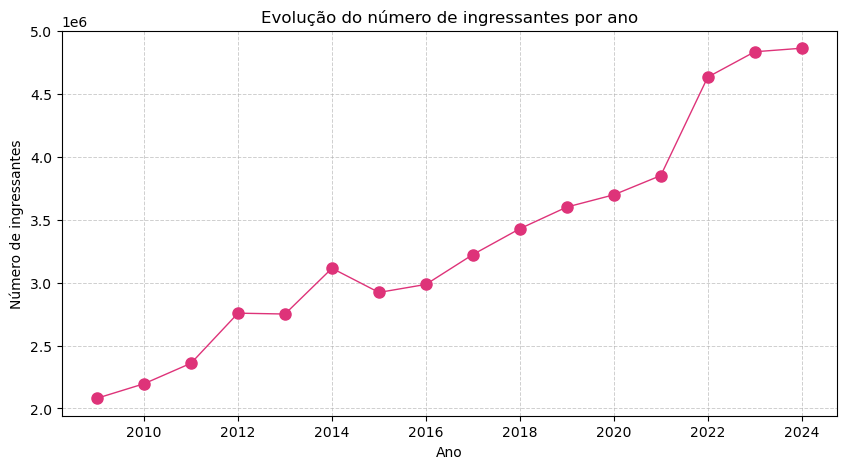

In [97]:
ingressantes_por_ano = (
    cursos
    .groupby('NU_ANO_CENSO')['QT_ING']
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ingressantes_por_ano.index,   # Anos
    ingressantes_por_ano.values,  # Valores de cada ano
    marker='o',
    markersize=8,
    color='#DE3379',
    lw=1,
    ls='-'
)

ax.set_xlabel('Ano')
ax.set_ylabel('Número de ingressantes')
ax.set_title('Evolução do número de ingressantes por ano')

ax.grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# Salvar o gráfico em disco
fig.savefig(
    'evolucao_ingressantes_por_ano.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

O gráfico mostra uma tendência geral de crescimento do número de ingressantes no ensino superior entre 2009 e 2024, com pequenas reduções nos períodos de 2012 a 2013 e de 2014 a 2015. O maior crescimento ocorreu entre 2021 e 2022.

> **Como os ingressantes estão distribuídos entre as diferentes regiões do Brasil?**

In [98]:
cursos.groupby('NO_REGIAO')['QT_ING'].sum()

NO_REGIAO
Centro-Oeste     5150701.0
Nordeste        10035780.0
Norte            4157031.0
Sudeste         24859169.0
Sul              9090326.0
Name: QT_ING, dtype: float64

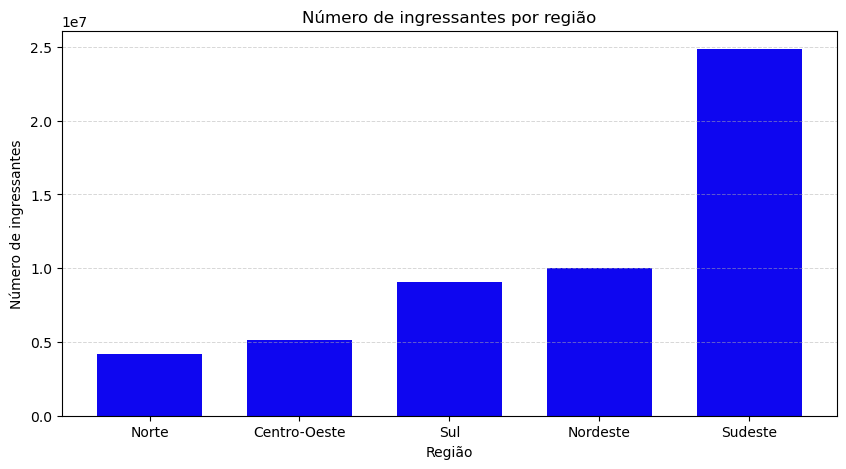

In [100]:
ingressantes_por_regiao = (
    cursos
    .groupby('NO_REGIAO')['QT_ING']
    .sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    ingressantes_por_regiao.index,
    ingressantes_por_regiao.values,
    color='#0E06F0',
    width=0.7
)

# ax.bar_label(barras,padding=3)

ax.set_xlabel('Região')
ax.set_ylabel('Número de ingressantes')
ax.set_title('Número de ingressantes por região')

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_ingressantes_por_regiao.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

No gráfico acima, vemos que a quantidade de ingressantes no ensino superior no período de 2009 a 2024 está distribuída de modo que as regiões Norte e Sudeste têm, respectivamente, a menor e a maior quantidade de ingressantes, sendo a quantidade de ingressantes correspondente à região Sudeste cerca de seis vezes maior que a quantidade de ingressantes correspondente à região Norte. Uma possível explicação para esse cenário reside no dato de que a região Sudeste é a que contém a maior quantidade total de vagas disponíveis no ensino superior, o que é evidenciado pelo gráfico a seguir que mostra a distribuição do total de vagas por região. 

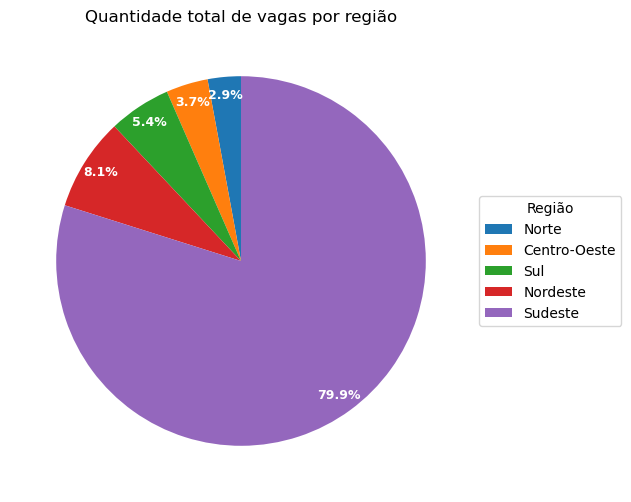

In [101]:
ingressantes_por_regiao = (
    cursos
    .groupby('NO_REGIAO')['QT_VG_TOTAL']
    .sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

# Gráfico de setores
wedges, textos, porcentagens = ax.pie(
    ingressantes_por_regiao.values,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.9,
    textprops={
        'color': 'white',
        'fontweight': 'bold',
        'fontsize': 9
    }
)

# Legenda
ax.legend(
    wedges,
    ingressantes_por_regiao.index,
    title='Região',
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)

ax.set_title('Quantidade total de vagas por região')



plt.show()

> **Quais estados apresentam os maiores números de ingressantes?**

In [102]:
cursos.groupby('NO_UF')['QT_ING'].sum()

NO_UF
Acre                     220385.0
Alagoas                  587698.0
Amapá                    259208.0
Amazonas                1003319.0
Bahia                   2543248.0
Ceará                   1642964.0
Distrito Federal        1463635.0
Espírito Santo           961544.0
Goiás                   1696481.0
Maranhão                 934313.0
Mato Grosso             1097047.0
Mato Grosso do Sul       893538.0
Minas Gerais            4926743.0
Paraná                  3509509.0
Paraíba                  855477.0
Pará                    1606704.0
Pernambuco              1660121.0
Piauí                    627266.0
Rio Grande do Norte      704104.0
Rio Grande do Sul       3216933.0
Rio de Janeiro          4598661.0
Rondônia                 481248.0
Roraima                  176889.0
Santa Catarina          2363884.0
Sergipe                  480589.0
São Paulo              14372221.0
Tocantins                409278.0
Name: QT_ING, dtype: float64

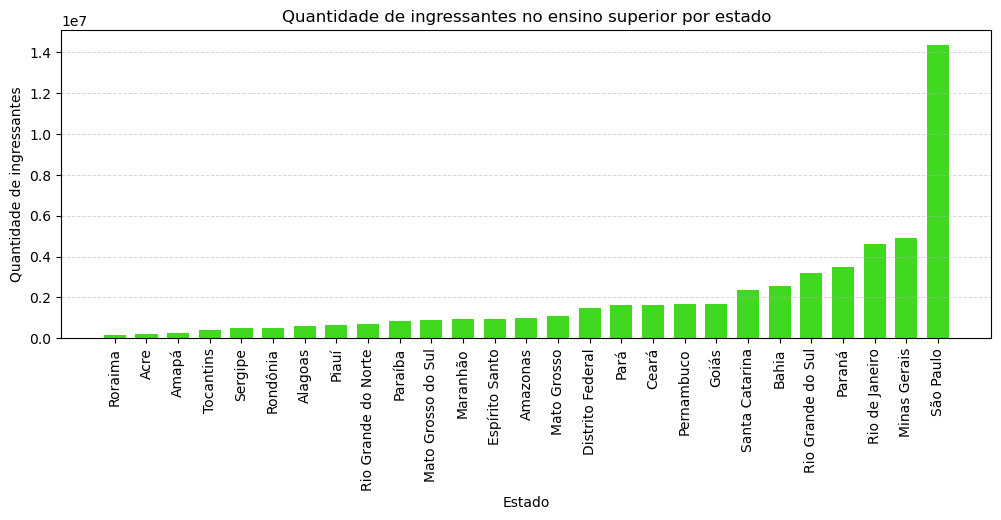

In [104]:
ingressantes_por_regiao = (
    cursos.groupby('NO_UF')['QT_ING'].sum().sort_values()
)

fig, ax = plt.subplots(figsize=(12, 4))

barras = ax.bar(
    ingressantes_por_regiao.index,
    ingressantes_por_regiao.values,
    color='#40D920',
    width=0.7
)

# ax.bar_label(barras,padding=3)

ax.set_xlabel('Estado')
ax.set_ylabel('Quantidade de ingressantes')
ax.set_title('Quantidade de ingressantes no ensino superior por estado')

# Rotaciona os rótulos do eixo x
ax.tick_params(axis='x', labelrotation=90)

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

# Salvar o gráfico em disco
fig.savefig(
    'quant_ingressantes_por_estado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

O gráfico acima nos mostra que a quantidade de ingressantes no ensino superior é maior nos estados das regiões Sul e Sudeste, especialmente no estado de São Paulo, que tem cerca de três vezes mais ingressantes que o estado de Minas gerais, que fica em segundo lugar no ranking.

> **Como evoluiu o número de ingressantes em cada região ao longo do período analisado?**

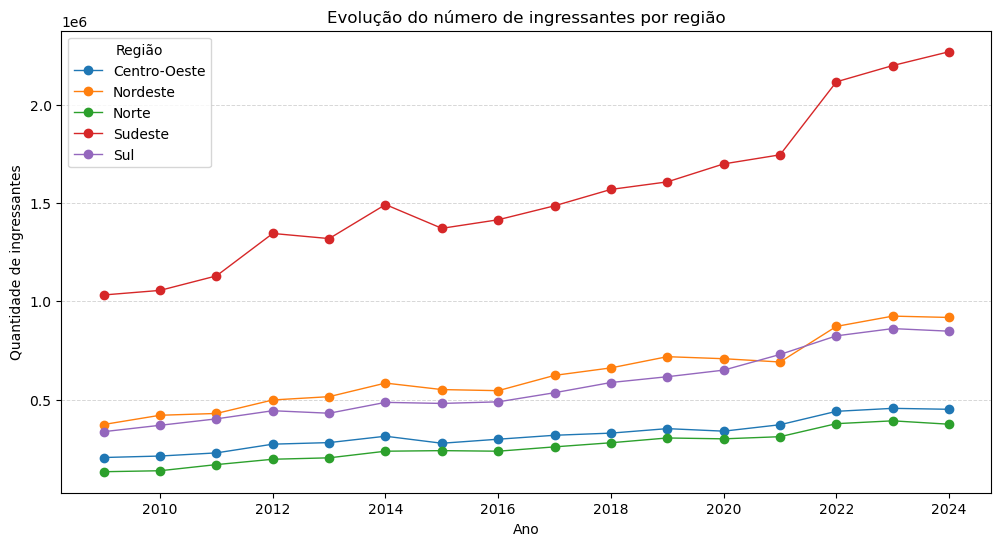

In [106]:
ingressantes_ano_regiao = (
    cursos
    .groupby(['NU_ANO_CENSO', 'NO_REGIAO'])['QT_ING']
    .sum()
    .unstack()
)

fig, ax = plt.subplots(figsize=(12, 6))

ingressantes_ano_regiao.plot(
    ax=ax,
    marker='o',
    linewidth=1
)

ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de ingressantes')
ax.set_title('Evolução do número de ingressantes por região')

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

ax.legend(title='Região')

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_ingressantes_por_regiao.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

A evolução do número de ingressantes no ensino superior em cada região, de 2009 a 2024, manteve, em geral, um padrão de crescimento, sendo a região Sudeste aquela cujo crescimento de ingressantes é mais acentuado em relação às demais regiões do país.

### 3.2 Evolução do número de cursos

> **Como evoluiu o número total de cursos de ensino superior no Brasil entre 2009 e 2024?**


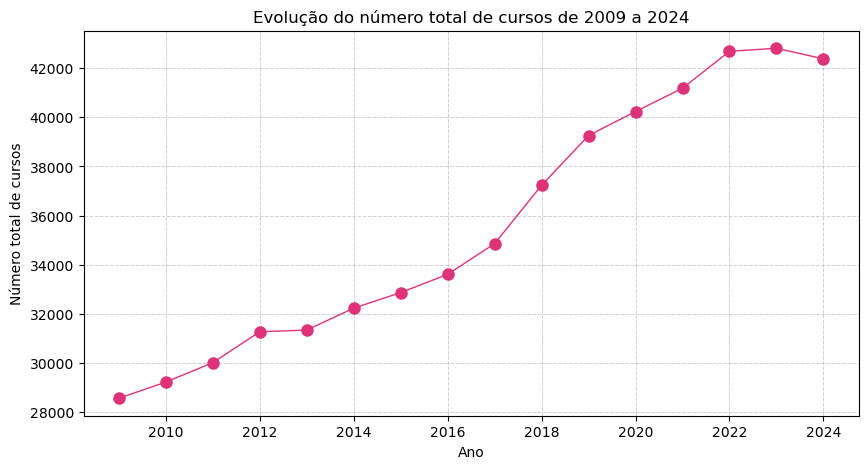

In [107]:
total_de_cursos = (
    cursos.groupby('NU_ANO_CENSO')['QT_CURSO'].sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    total_de_cursos.index,      # ANOS
    total_de_cursos.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = '#DE3379',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Número total de cursos')
plt.title('Evolução do número total de cursos de 2009 a 2024')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

A evolução do número total de cursos no perído em questão manteve uma tendência geral de crescimento, sendo o período de 2017 a 2019 com o crescimento mais acelerado. Houve uma ligeira queda da evolução de 2023 a 2024.

> **Qual foi a variação percentual do número de cursos entre 2009 e 2024?**


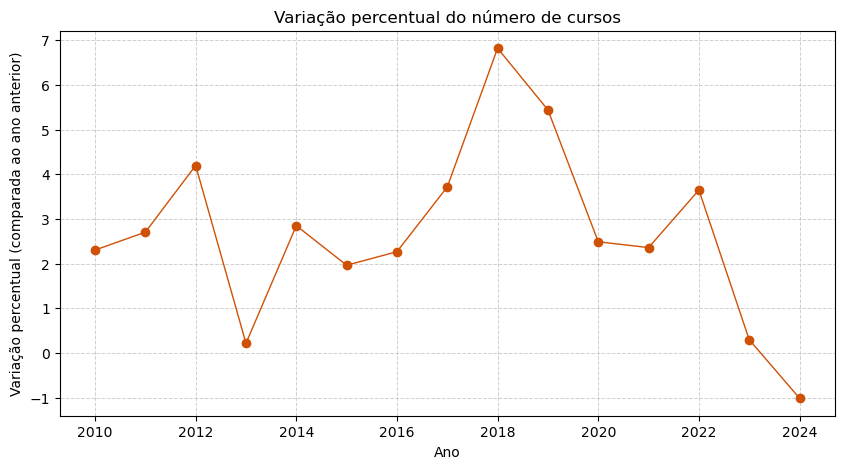

In [108]:
cursos_por_ano = cursos.groupby('NU_ANO_CENSO')['QT_CURSO'].sum()
variacao_percent_cursos = cursos_por_ano.pct_change() * 100

plt.figure(figsize=(10, 5))

plt.plot(
    variacao_percent_cursos.index,      # ANOS
    variacao_percent_cursos.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 6,                  # TAMANHO DO MARCADOR
    color = '#CF5105',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Variação percentual (comparada ao ano anterior)')
plt.title('Variação percentual do número de cursos')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

A variação percentual anual do número de cursos foi positiva na maior parte do período analisado, indicando crescimento do número de cursos entre 2009 e 2024. O maior crescimento ocorreu em 2018, quando o número de cursos aumentou aproximadamente 6,82% em relação a 2017. Após esse período, observa-se uma desaceleração do crescimento, com pequenas oscilações até 2022. Em 2023, o crescimento foi praticamente nulo, de aproximadamente 0,30%, enquanto em 2024 ocorreu uma redução de cerca de 1,01% em relação ao ano anterior.

> **Em quais anos ocorreram os maiores aumentos e reduções no número de cursos?**


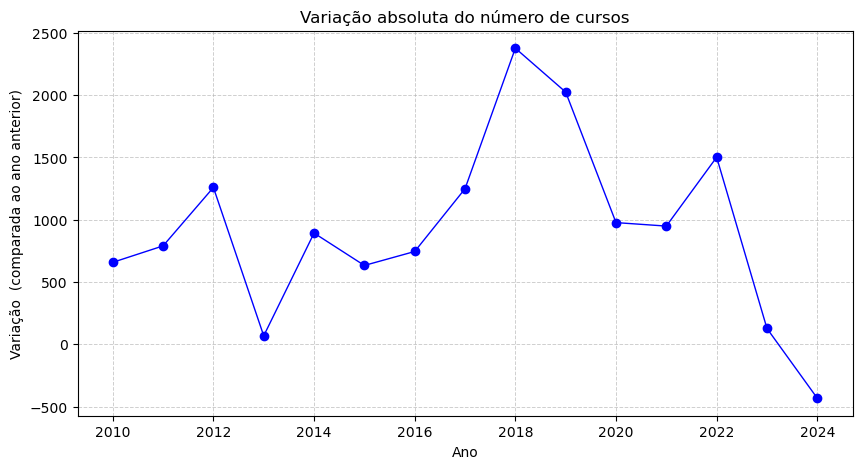

In [109]:
cursos_por_ano = cursos.groupby('NU_ANO_CENSO')['QT_CURSO'].sum()
variacao_cursos = cursos_por_ano.diff()

plt.figure(figsize=(10, 5))

plt.plot(
    variacao_cursos.index,      # ANOS
    variacao_cursos.values,     # VALORES DE CADA ANO
    marker='o',                 # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 6,             # TAMANHO DO MARCADOR
    color = 'blue',             # COR DA LINHA
    lw = 1,                     # ESPESSURA DA LINHA 
    ls = '-',                   # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Variação  (comparada ao ano anterior)')
plt.title('Variação absoluta do número de cursos')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

A maior variação positiva no número de cursos ocorreu em 2018, com um aumento de aproximadamente 2.380 cursos em relação ao ano anterior. A maior redução ocorreu em 2024, quando foram registrados aproximadamente 430 cursos a menos que em 2023.

> **Como o número de cursos evoluiu nas diferentes regiões brasileiras ao longo do período de 2009 a 2024?**


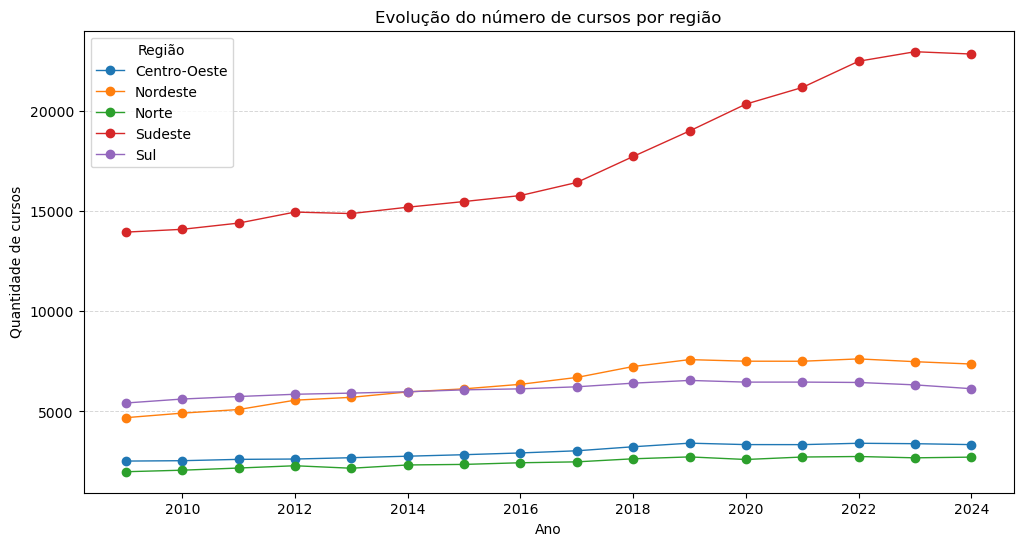

In [110]:
cursos_por_ano_regiao = cursos.groupby(['NU_ANO_CENSO', 'NO_REGIAO'])['QT_CURSO'].sum().unstack()


fig, ax = plt.subplots(figsize=(12, 6))

cursos_por_ano_regiao.plot(
    ax=ax,
    marker='o',
    linewidth=1
)

ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de cursos')
ax.set_title('Evolução do número de cursos por região')

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

ax.legend(title='Região')

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_cursos_por_regiao.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

A evolução do número de cursos tem uma tendência geral crescente em todas as regiões, porém com padrões de crescimento distintos. A quantidade de cursos no período de 2009 a 2024 para as regiões Norte e Centro-oeste manteve-se aproximadamente constante. Já para a região Sul, embora a variação dessa quantidade seja pequena, houve uma leve tendÊncia de decrescimento a partir de 2019. No período considerado, a região sudeste destaca-se por ter as maiores quantidades de curso em todos os anos, além de apresentar umcrescimento acelerado dessa quantidade a partir de 2016, com uma dicreta desaceleração entre 2023 e 2024.

> **Quais estados apresentaram os maiores e os menores números de cursos ao longo do período analisado?**

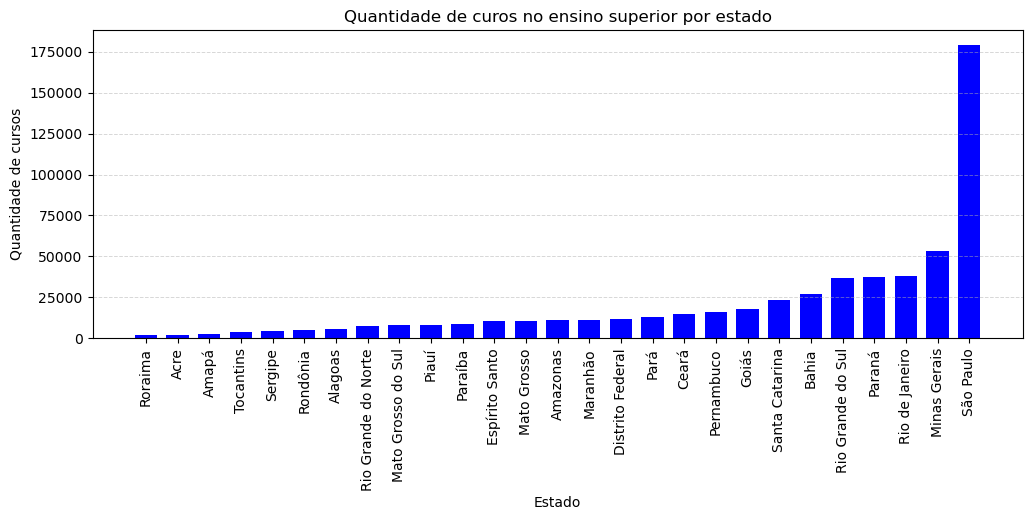

In [112]:
cursos_por_regiao = (
    cursos.groupby('NO_UF')['QT_CURSO'].sum().sort_values()
)

fig, ax = plt.subplots(figsize=(12, 4))

barras = ax.bar(
    cursos_por_regiao.index,
    cursos_por_regiao.values,
    color='blue',
    width=0.7
)

# ax.bar_label(barras,padding=3)

ax.set_xlabel('Estado')
ax.set_ylabel('Quantidade de cursos')
ax.set_title('Quantidade de curos no ensino superior por estado')

# Rotaciona os rótulos do eixo x
ax.tick_params(axis='x', labelrotation=90)

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

# Salvar o gráfico em disco
fig.savefig(
    'quant_cursos_por_estado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Os estados de Roraima e São Paulo apresentaram, respectivamente, o menor e o maior número de cursos ao longo do período analisado.

### 3.3 Evolução do número de vagas


> **Como o número total de vagas ofertadas no ensino superior evoluiu ao longo do período de 2009 a 2024?**


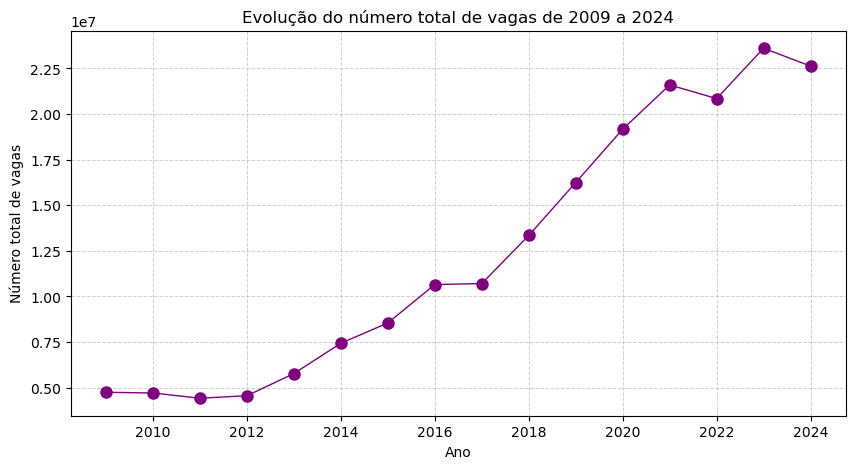

In [113]:
total_de_vagas = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL'].sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    total_de_vagas.index,      # ANOS
    total_de_vagas.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'purple',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Número total de vagas')
plt.title('Evolução do número total de vagas de 2009 a 2024')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

O número total de vagas no ensino superior para o período considerado evoluiu com tendência geral crescente, exceto nos períodos de 2010 a 2011 e 2023 a 2024. Nota-se uma acentuada aceleração nesse crescimento no período de 2017 a 2021. No gráfico a seguir temos a evolução do número de vagas por gerião, onde vemos que a região Sudeste destaca-se nesse cenário por ter as maiores quantidades de vaga em todo o período. Observa-se também que essa quantidade teve tendência geral crescente até 2015 em todas as regiões e tendência de decrescimento a partir de 2021.

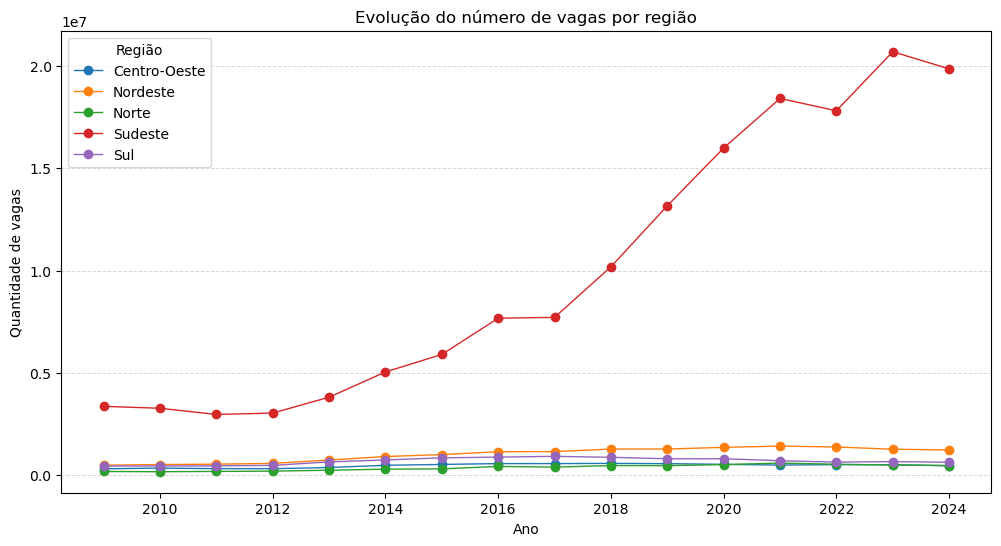

In [115]:
vagas_por_ano_regiao = cursos.groupby(['NU_ANO_CENSO', 'NO_REGIAO'])['QT_VG_TOTAL'].sum().unstack()


fig, ax = plt.subplots(figsize=(12, 6))

vagas_por_ano_regiao.plot(
    ax=ax,
    marker='o',
    linewidth=1
)

ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de vagas')
ax.set_title('Evolução do número de vagas por região')

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

ax.legend(title='Região')

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_vagas_por_regiao.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Os gráficos a seguir nos mostram a evolução do número de vagas por tipo de vaga. Esses gráficos mostram que, de 2009 a 2013, a evolução do total de vagas permaneceu estagnada em torno de zero, o que seria uma possível explicação para o fato de que o total de vagas em cada região permaneceu com pouca variação no período de 2009 a 2012. 

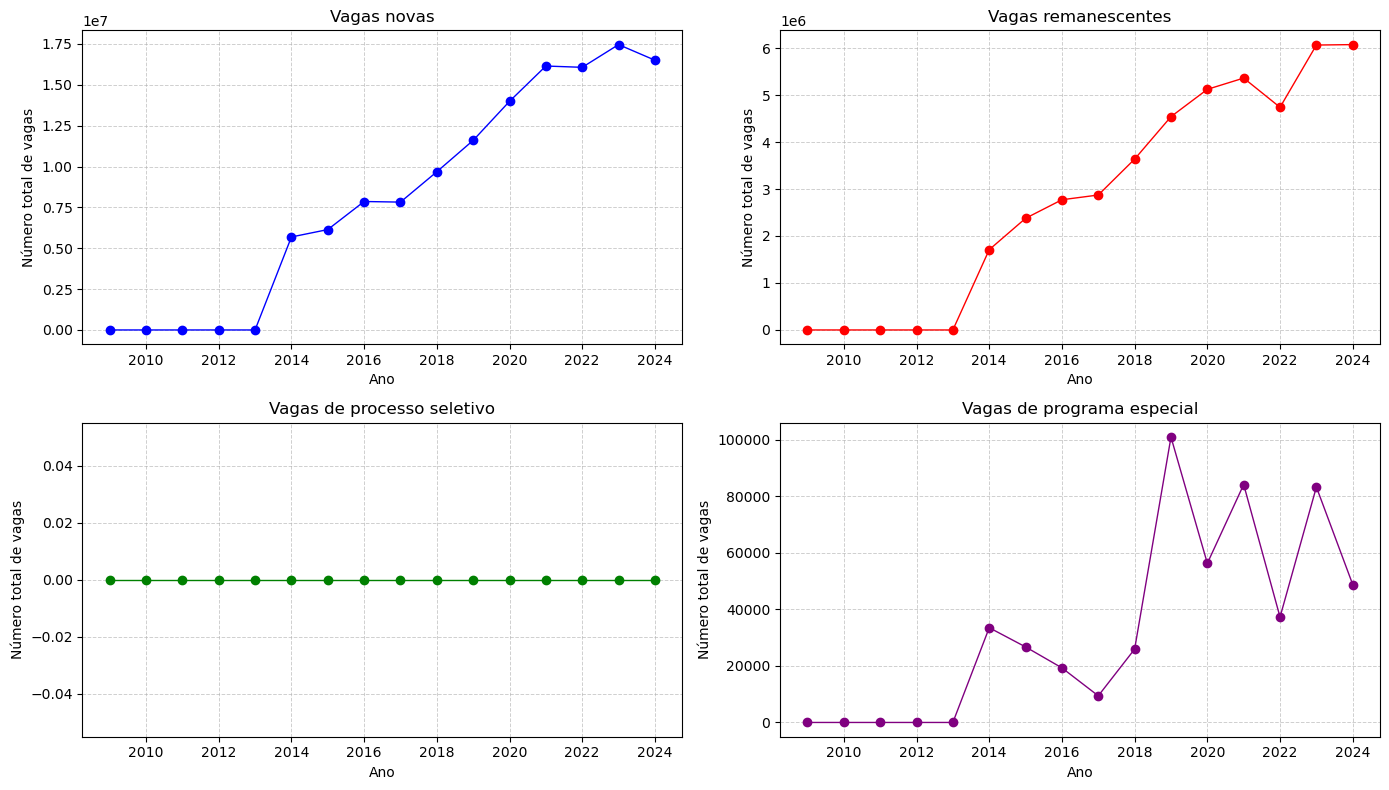

In [116]:
total_vagas_novas = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_NOVA'].sum()
)

total_vagas_remanescentes = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_REMANESC'].sum()
)

total_vagas_proc_sel = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_PROC_SELETIVO'].sum()
)

total_vagas_prog_esp = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_PROG_ESPECIAL'].sum()
)


# ==========================================================================
# CRIAÇÃO DOS SUBPLOTS
# ==========================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 8)
)


# ==========================================================================
# 1. VAGAS NOVAS
# ==========================================================================

axes[0, 0].plot(
    total_vagas_novas.index,
    total_vagas_novas.values,
    marker='o',
    markersize=6,
    color='blue',
    lw=1,
    ls='-'
)

axes[0, 0].set_xlabel('Ano')
axes[0, 0].set_ylabel('Número total de vagas')
axes[0, 0].set_title('Vagas novas')

axes[0, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 2. VAGAS REMANESCENTES
# ==========================================================================

axes[0, 1].plot(
    total_vagas_remanescentes.index,
    total_vagas_remanescentes.values,
    marker='o',
    markersize=6,
    color='red',
    lw=1,
    ls='-'
)

axes[0, 1].set_xlabel('Ano')
axes[0, 1].set_ylabel('Número total de vagas')
axes[0, 1].set_title('Vagas remanescentes')

axes[0, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 3. VAGAS DE PROCESSO SELETIVO
# ==========================================================================

axes[1, 0].plot(
    total_vagas_proc_sel.index,
    total_vagas_proc_sel.values,
    marker='o',
    markersize=6,
    color='green',
    lw=1,
    ls='-'
)

axes[1, 0].set_xlabel('Ano')
axes[1, 0].set_ylabel('Número total de vagas')
axes[1, 0].set_title('Vagas de processo seletivo')

axes[1, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 4. VAGAS DE PROGRAMA ESPECIAL
# ==========================================================================

axes[1, 1].plot(
    total_vagas_prog_esp.index,
    total_vagas_prog_esp.values,
    marker='o',
    markersize=6,
    color='purple',
    lw=1,
    ls='-'
)

axes[1, 1].set_xlabel('Ano')
axes[1, 1].set_ylabel('Número total de vagas')
axes[1, 1].set_title('Vagas de programa especial')

axes[1, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# AJUSTE DO ESPAÇAMENTO
# ==========================================================================

plt.tight_layout()

plt.show()

A seguir, vemos a evolução do total de vagas por turno (diurno e noturno). Para ambos turnos, nota-se um crescimento acelerado do total de vagas entre 2012 e 2016, com tendência geral de queda a partir de 2018.

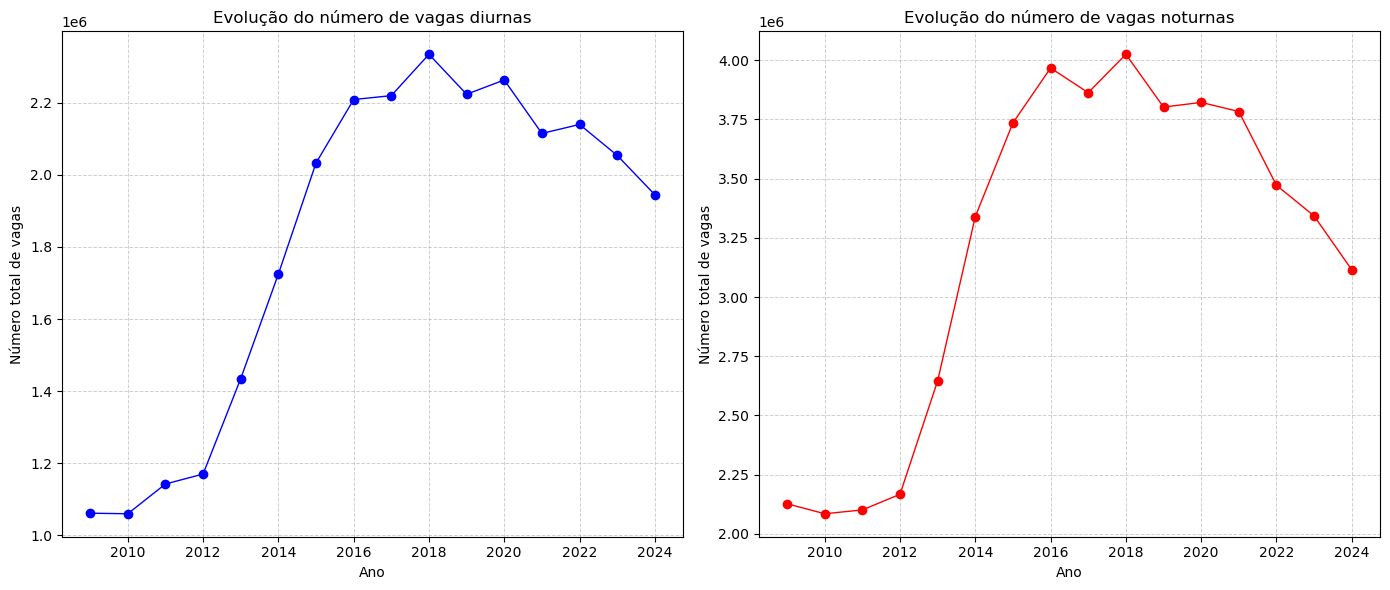

In [117]:
total_vagas_diurno = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL_DIURNO'].sum()
)

total_vagas_noturno = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL_NOTURNO'].sum()
)


# ==========================================================================
# CRIAÇÃO DOS SUBPLOTS
# ==========================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)


# ==========================================================================
# 1. VAGAS DIURNAS
# ==========================================================================

axes[0].plot(
    total_vagas_diurno.index,
    total_vagas_diurno.values,
    marker='o',
    markersize=6,
    color='blue',
    lw=1,
    ls='-'
)

axes[0].set_xlabel('Ano')
axes[0].set_ylabel('Número total de vagas')
axes[0].set_title('Evolução do número de vagas diurnas')

axes[0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 2. VAGAS NOTURNAS
# ==========================================================================

axes[1].plot(
    total_vagas_noturno.index,
    total_vagas_noturno.values,
    marker='o',
    markersize=6,
    color='red',
    lw=1,
    ls='-'
)

axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Número total de vagas')
axes[1].set_title('Evolução do número de vagas noturnas')

axes[1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# AJUSTE DO ESPAÇAMENTO
# ==========================================================================

plt.tight_layout()

plt.show()

O gráfico a seguir mostra que a quanidade de vagas em cursos EAD teve um acentuado crescimento entre 2017 e 2023.

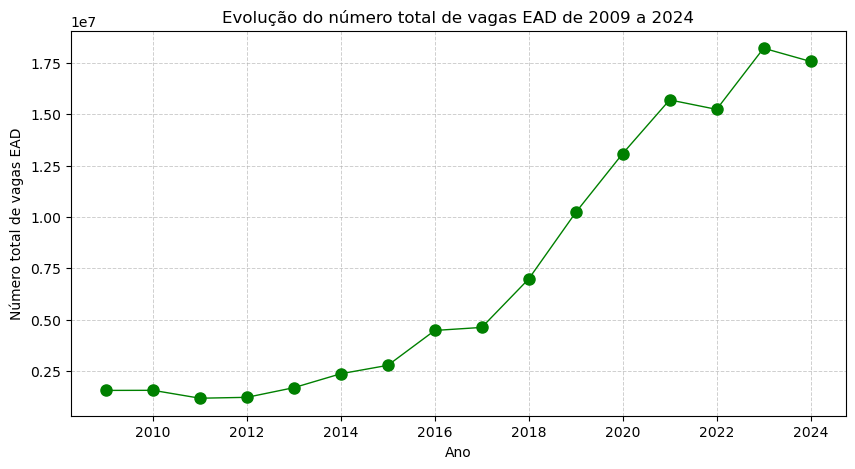

In [118]:
total_de_vagas_EAD = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL_EAD'].sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    total_de_vagas_EAD.index,      # ANOS
    total_de_vagas_EAD.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'green',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Número total de vagas EAD')
plt.title('Evolução do número total de vagas EAD de 2009 a 2024')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

> **Como as vagas ofertadas estão distribuídas entre os diferentes estados brasileiros?**


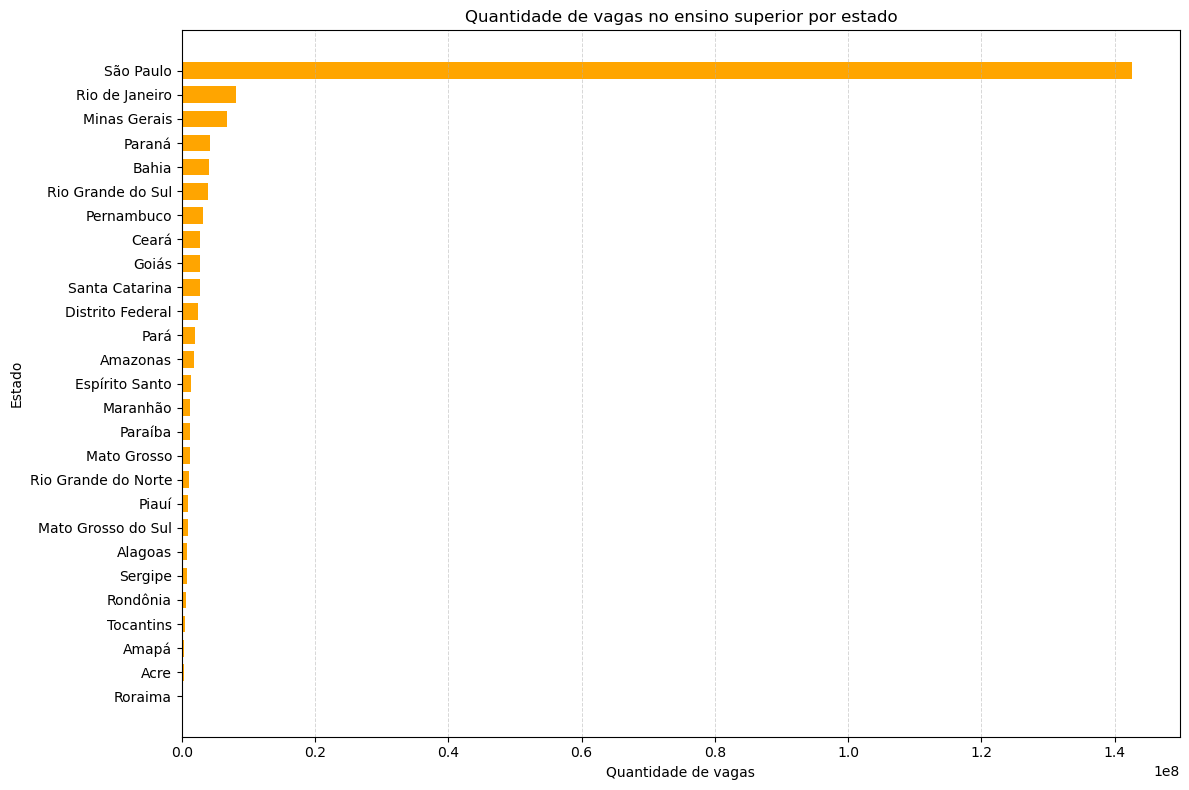

In [120]:
vagas_por_UF = (
    cursos
    .groupby('NO_UF')['QT_VG_TOTAL']
    .sum()
    .sort_values()
)


fig, ax = plt.subplots(figsize=(12, 8))

barras = ax.barh(
    vagas_por_UF.index,
    vagas_por_UF.values,
    color='orange',
    height=0.7
)

# ax.bar_label(barras, padding=3)

ax.set_xlabel('Quantidade de vagas')
ax.set_ylabel('Estado')
ax.set_title('Quantidade de vagas no ensino superior por estado')

ax.grid(
    axis='x',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

plt.tight_layout()

# Salvar o gráfico em disco
fig.savefig(
    'quant_vagas_por_estado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

> **Qual foi a variação percentual do número de vagas ofertadas de um ano para o outro ao longo do período analisado?**


In [ ]:
variacao_percent_vagas

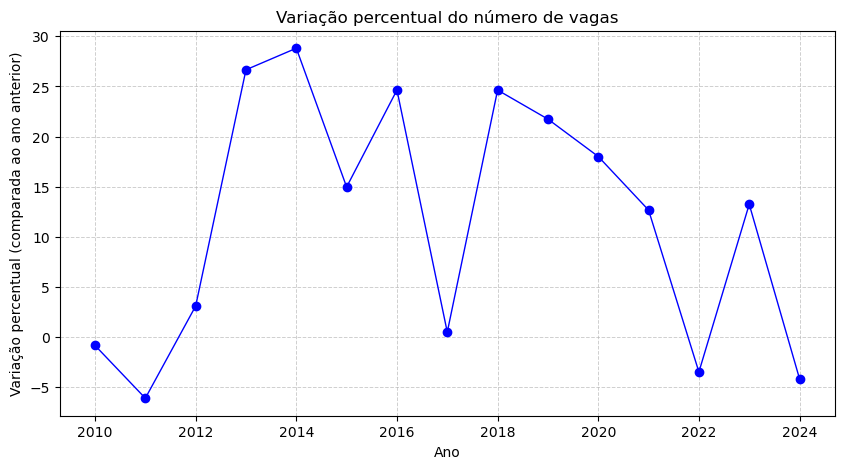

In [121]:
vagas_por_ano = cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL'].sum()
variacao_percent_vagas = vagas_por_ano.pct_change() * 100

plt.figure(figsize=(10, 5))

plt.plot(
    variacao_percent_vagas.index,      # ANOS
    variacao_percent_vagas.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 6,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Variação percentual (comparada ao ano anterior)')
plt.title('Variação percentual do número de vagas')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

> **Qual foi a taxa de ocupação das vagas ofertadas no ensino superior ao longo do período de 2009 a 2024?**

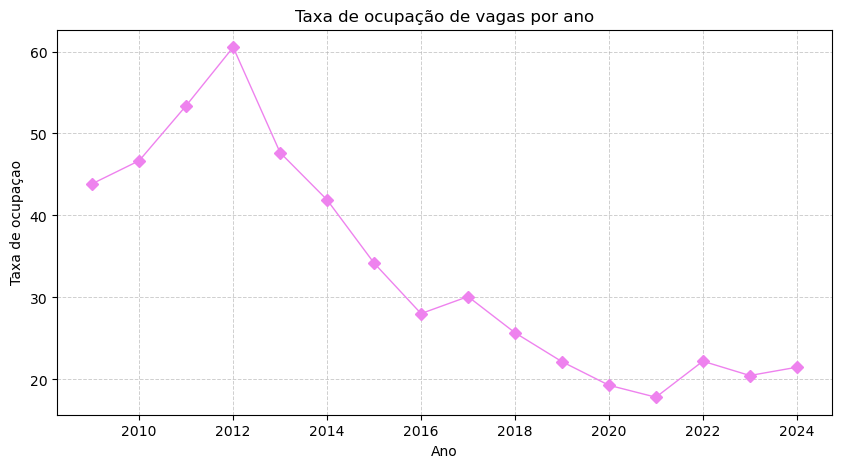

In [122]:
vagas_por_ano = (
    cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL'].sum()
)

ingressantes_por_ano = (
    cursos.groupby('NU_ANO_CENSO')['QT_ING'].sum()
)

taxa_ocupacao_por_ano = (
    ingressantes_por_ano / vagas_por_ano
) * 100


plt.figure(figsize=(10, 5))

plt.plot(
    taxa_ocupacao_por_ano.index,      # ANOS
    taxa_ocupacao_por_ano.values,     # VALORES DE CADA ANO
    marker='D',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 6,                  # TAMANHO DO MARCADOR
    color = 'violet',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Taxa de ocupaçao')
plt.title('Taxa de ocupação de vagas por ano')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

Observamos que a taxa de ocupação das vagas tem uma tendência geral decrescente de 2012 a 2021, embora o número total de vagas tenha crescido nesse período. Vamos evidenciar este fato construindouma regressãoentre duas variáveis, a saber, `Taxa_ocupação` e `Total_vagas`.

In [123]:
df_1 = pd.DataFrame({
    'Ano': taxa_ocupacao_por_ano.index,
    'Taxa_ocupação': taxa_ocupacao_por_ano.values
})

print(df_1)

     Ano  Taxa_ocupação
0   2009      43.874184
1   2010      46.687265
2   2011      53.401116
3   2012      60.522693
4   2013      47.665582
5   2014      41.899084
6   2015      34.193719
7   2016      28.033647
8   2017      30.108911
9   2018      25.696420
10  2019      22.167609
11  2020      19.292272
12  2021      17.831315
13  2022      22.223737
14  2023      20.477581
15  2024      21.489329


In [124]:
df_2 = pd.DataFrame({
    'Ano': cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL'].sum().index,
    'Total_vagas': cursos.groupby('NU_ANO_CENSO')['QT_VG_TOTAL'].sum().values
})

print(df_2)

     Ano  Total_vagas
0   2009    4743605.0
1   2010    4704527.0
2   2011    4418314.0
3   2012    4555450.0
4   2013    5769853.0
5   2014    7431857.0
6   2015    8544581.0
7   2016   10649813.0
8   2017   10703934.0
9   2018   13340625.0
10  2019   16240475.0
11  2020   19165498.0
12  2021   21593500.0
13  2022   20844654.0
14  2023   23606104.0
15  2024   22626104.0


In [125]:
df = pd.concat([df_1, df_2['Total_vagas']], axis=1)

In [126]:
df

,Ano,Taxa_ocupação,Total_vagas
0,2009,43.874184,4743605.0
1,2010,46.687265,4704527.0
2,2011,53.401116,4418314.0
3,2012,60.522693,4555450.0
4,2013,47.665582,5769853.0
5,2014,41.899084,7431857.0
6,2015,34.193719,8544581.0
7,2016,28.033647,10649813.0
8,2017,30.108911,10703934.0
9,2018,25.696420,13340625.0


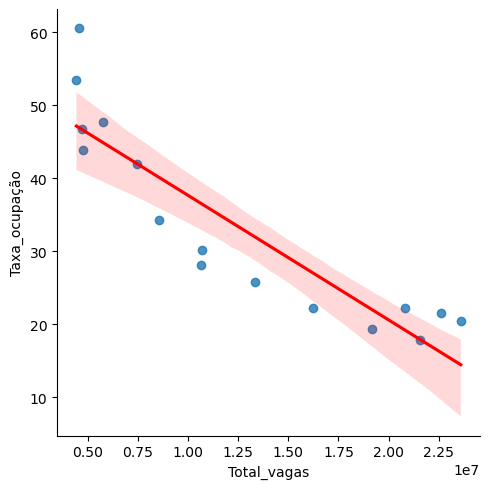

In [127]:
sns.lmplot(
    x='Total_vagas',
    y='Taxa_ocupação',
    data=df,
    palette='blue',
    line_kws={'color': 'red'}
)

Este gráfico mostra que, embora a quantidade total de vagas tenha crescido no período considerdo, a taxa de ocupação dessas vagas teve uma tendência geral decrescente no mesmo período.

### 3.4 Evolução das matrículas


> **Como o número total de matrículas no ensino superior evoluiu ao longo do período de 2009 a 2024?**
   - Variável: `QT_MAT`


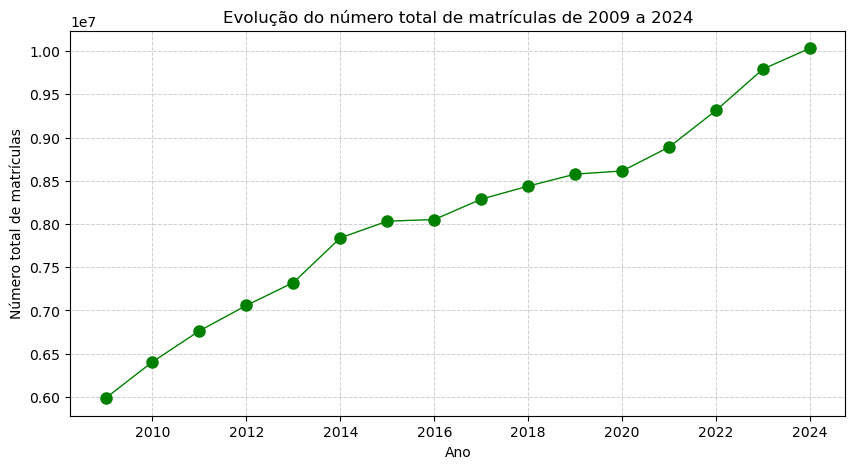

In [128]:
total_de_mat = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT'].sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    total_de_mat.index,      # ANOS
    total_de_mat.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'green',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Número total de matrículas')
plt.title('Evolução do número total de matrículas de 2009 a 2024')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

> **Como as matrículas estão distribuídas entre as diferentes faixas etárias e como essa distribuição evoluiu ao longo do período analisado?**

Os gráficos a seguir mostram a evoluçao da quantidade de matrículas por faixa etária, no período de 2009 a 2024. Vemos que, com exceção da faixa etária de 0 a 17 anos, todas as demais apresentam tendência geral crescente do npumero de matrículas, com pouco ou nenhum decrescimento.


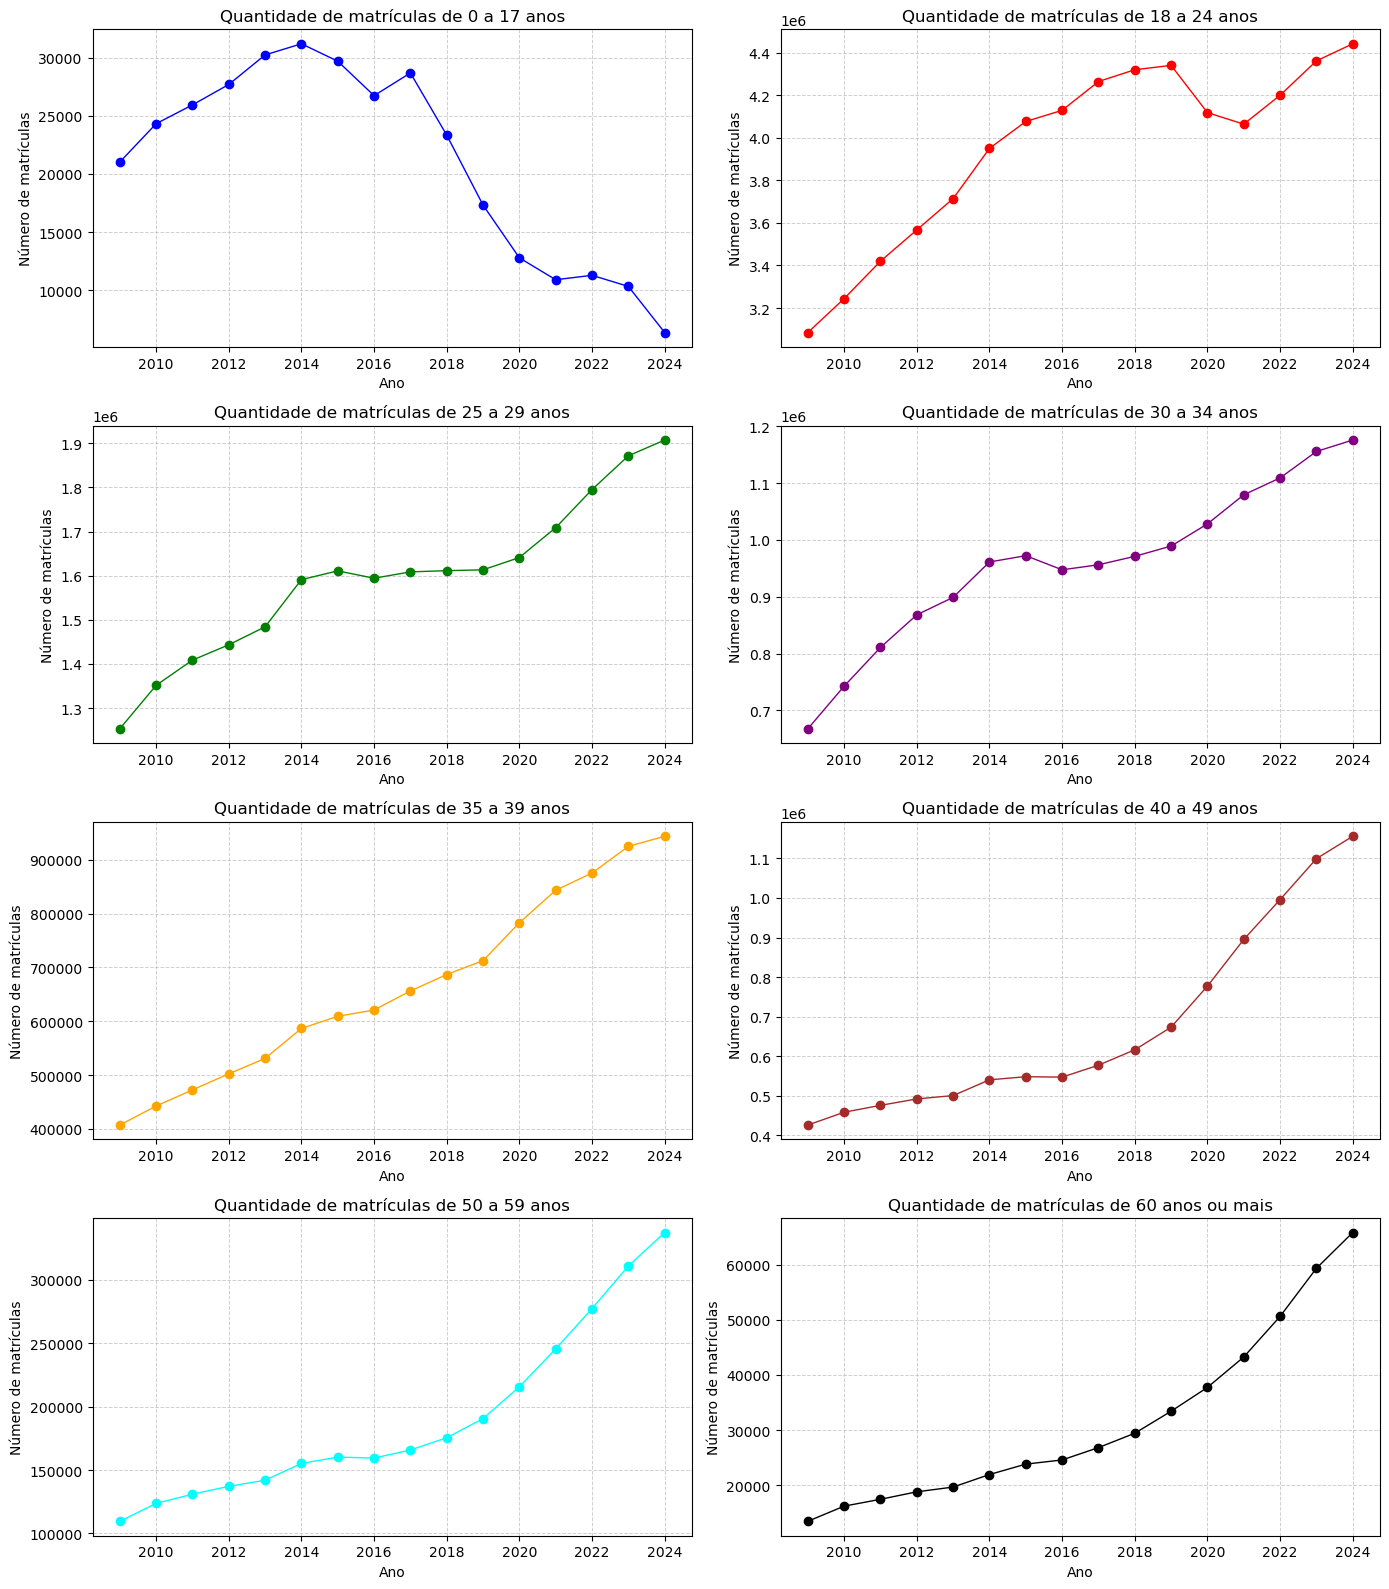

In [129]:
# ==========================================================================
# AGRUPAMENTO POR ANO
# ==========================================================================

mat_0_17 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_0_17'].sum()
)

mat_18_24 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_18_24'].sum()
)

mat_25_29 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_25_29'].sum()
)

mat_30_34 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_30_34'].sum()
)

mat_35_39 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_35_39'].sum()
)

mat_40_49 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_40_49'].sum()
)

mat_50_59 = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_50_59'].sum()
)

mat_60_MAIS = (
    cursos.groupby('NU_ANO_CENSO')['QT_MAT_60_MAIS'].sum()
)


# ==========================================================================
# CRIAÇÃO DOS SUBPLOTS
# ==========================================================================

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 16)
)


# ==========================================================================
# 1. 0 a 17 anos
# ==========================================================================

axes[0, 0].plot(
    mat_0_17.index,
    mat_0_17.values,
    marker='o',
    markersize=6,
    color='blue',
    lw=1,
    ls='-'
)

axes[0, 0].set_xlabel('Ano')
axes[0, 0].set_ylabel('Número de matrículas')
axes[0, 0].set_title('Quantidade de matrículas de 0 a 17 anos')

axes[0, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 2. 18 a 24 anos
# ==========================================================================

axes[0, 1].plot(
    mat_18_24.index,
    mat_18_24.values,
    marker='o',
    markersize=6,
    color='red',
    lw=1,
    ls='-'
)

axes[0, 1].set_xlabel('Ano')
axes[0, 1].set_ylabel('Número de matrículas')
axes[0, 1].set_title('Quantidade de matrículas de 18 a 24 anos')

axes[0, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 3. 25 a 29 anos
# ==========================================================================

axes[1, 0].plot(
    mat_25_29.index,
    mat_25_29.values,
    marker='o',
    markersize=6,
    color='green',
    lw=1,
    ls='-'
)

axes[1, 0].set_xlabel('Ano')
axes[1, 0].set_ylabel('Número de matrículas')
axes[1, 0].set_title('Quantidade de matrículas de 25 a 29 anos')

axes[1, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 4. 30 a 34 anos
# ==========================================================================

axes[1, 1].plot(
    mat_30_34.index,
    mat_30_34.values,
    marker='o',
    markersize=6,
    color='purple',
    lw=1,
    ls='-'
)

axes[1, 1].set_xlabel('Ano')
axes[1, 1].set_ylabel('Número de matrículas')
axes[1, 1].set_title('Quantidade de matrículas de 30 a 34 anos')

axes[1, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 5. 35 a 39 anos
# ==========================================================================

axes[2, 0].plot(
    mat_35_39.index,
    mat_35_39.values,
    marker='o',
    markersize=6,
    color='orange',
    lw=1,
    ls='-'
)

axes[2, 0].set_xlabel('Ano')
axes[2, 0].set_ylabel('Número de matrículas')
axes[2, 0].set_title('Quantidade de matrículas de 35 a 39 anos')

axes[2, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 6. 40 a 49 anos
# ==========================================================================

axes[2, 1].plot(
    mat_40_49.index,
    mat_40_49.values,
    marker='o',
    markersize=6,
    color='brown',
    lw=1,
    ls='-'
)

axes[2, 1].set_xlabel('Ano')
axes[2, 1].set_ylabel('Número de matrículas')
axes[2, 1].set_title('Quantidade de matrículas de 40 a 49 anos')

axes[2, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 7. 50 a 59 anos
# ==========================================================================

axes[3, 0].plot(
    mat_50_59.index,
    mat_50_59.values,
    marker='o',
    markersize=6,
    color='cyan',
    lw=1,
    ls='-'
)

axes[3, 0].set_xlabel('Ano')
axes[3, 0].set_ylabel('Número de matrículas')
axes[3, 0].set_title('Quantidade de matrículas de 50 a 59 anos')

axes[3, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 8. 60 anos ou mais
# ==========================================================================

axes[3, 1].plot(
    mat_60_MAIS.index,
    mat_60_MAIS.values,
    marker='o',
    markersize=6,
    color='black',
    lw=1,
    ls='-'
)

axes[3, 1].set_xlabel('Ano')
axes[3, 1].set_ylabel('Número de matrículas')
axes[3, 1].set_title('Quantidade de matrículas de 60 anos ou mais')

axes[3, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# AJUSTE DO ESPAÇAMENTO
# ==========================================================================

plt.tight_layout()

plt.show()

Vejamos a seguir qual é a participação percentual de cada faixa etária na quantidade todtal de matrículas para o período de 2009 a 2024. Antes, porém, precisamos de alguma preparação nos dados.

In [130]:
total_mat = cursos.groupby('NU_ANO_CENSO')['QT_MAT'].sum()

mat_0_17 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_0_17'].sum()
mat_18_24 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_18_24'].sum()
mat_25_29 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_25_29'].sum()
mat_30_34 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_30_34'].sum()
mat_35_39 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_35_39'].sum()
mat_40_49 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_40_49'].sum()
mat_50_59 = cursos.groupby('NU_ANO_CENSO')['QT_MAT_50_59'].sum()
mat_60_MAIS = cursos.groupby('NU_ANO_CENSO')['QT_MAT_60_MAIS'].sum()

In [131]:
total_mat = total_mat.to_frame()

mat_0_17 = mat_0_17.to_frame()
mat_18_24 = mat_18_24.to_frame()
mat_25_29 = mat_25_29.to_frame()
mat_30_34 = mat_30_34.to_frame()
mat_35_39 = mat_35_39.to_frame()
mat_40_49 = mat_40_49.to_frame()
mat_50_59 = mat_50_59.to_frame()
mat_60_MAIS = mat_60_MAIS.to_frame() 

In [132]:
dataframes = [total_mat, mat_0_17, mat_18_24, mat_25_29, mat_30_34, mat_35_39, mat_40_49, mat_50_59, mat_60_MAIS]
df_1 = pd.concat(dataframes, axis=1)

O dataframe `df_1` mostra as quantidades de matrículas por faixa etária em cada ano.

In [133]:
df_1

,QT_MAT,QT_MAT_0_17,QT_MAT_18_24,QT_MAT_25_29,QT_MAT_30_34,QT_MAT_35_39,QT_MAT_40_49,QT_MAT_50_59,QT_MAT_60_MAIS
NU_ANO_CENSO,,,,,,,,,
2009,5983701.0,21023.0,3085197.0,1252921.0,667379.0,407220.0,425823.0,109526.0,13460.0
2010,6404611.0,24325.0,3244658.0,1351343.0,742493.0,442529.0,458236.0,123612.0,16203.0
2011,6763282.0,25945.0,3420246.0,1408535.0,810716.0,472514.0,475616.0,130936.0,17448.0
2012,7057814.0,27703.0,3567151.0,1443267.0,868150.0,502383.0,491813.0,137094.0,18801.0
2013,7322110.0,30248.0,3714139.0,1484104.0,898923.0,530984.0,500330.0,141961.0,19663.0
2014,7839437.0,31208.0,3949891.0,1590978.0,961244.0,586669.0,540142.0,155161.0,21934.0
2015,8032611.0,29708.0,4076082.0,1610864.0,972326.0,609245.0,548039.0,160183.0,23822.0
2016,8051548.0,26742.0,4128606.0,1594205.0,947463.0,620944.0,546927.0,159421.0,24576.0
2017,8287156.0,28697.0,4263691.0,1608598.0,956290.0,656343.0,577180.0,165803.0,26814.0


Faremos uma breve análise da consistência dos dados no dataframe. A seguir, temos a soma dos percentuais de matrículas para cada faixa etária.

In [134]:
p = (
df_1['QT_MAT_0_17'].sum()/df_1['QT_MAT'].sum()*100 
+ df_1['QT_MAT_18_24'].sum()/df_1['QT_MAT'].sum()*100
+ df_1['QT_MAT_25_29'].sum()/df_1['QT_MAT'].sum()*100
+ df_1['QT_MAT_30_34'].sum()/df_1['QT_MAT'].sum()*100
+ df_1['QT_MAT_35_39'].sum()/df_1['QT_MAT'].sum()*100
+ df_1['QT_MAT_40_49'].sum()/df_1['QT_MAT'].sum()*100
+ df_1['QT_MAT_50_59'].sum()/df_1['QT_MAT'].sum()*100
+ df_1['QT_MAT_60_MAIS'].sum()/df_1['QT_MAT'].sum()*100
)

In [135]:
p

99.9760268405416

In [136]:
percentuais = [df_1[coluna].sum()/df_1['QT_MAT'].sum()*100 for coluna in df_1.columns.to_list()[1:9]]

In [137]:
percentuais

[0.26110976115153756,
 48.909715823394954,
 19.70104151793885,
 11.850357285236209,
 8.190685487078001,
 8.328091056152214,
 2.346932281009879,
 0.38809362857995033]

Listamos as colunas do dataframe e fazemos uma pequena alteração em seus respectivos nomes.

In [138]:
df_1.columns.to_list()

['QT_MAT',
 'QT_MAT_0_17',
 'QT_MAT_18_24',
 'QT_MAT_25_29',
 'QT_MAT_30_34',
 'QT_MAT_35_39',
 'QT_MAT_40_49',
 'QT_MAT_50_59',
 'QT_MAT_60_MAIS']

In [139]:
faixas = df_1.columns.to_list()[1:9]

In [140]:
faixas

['QT_MAT_0_17',
 'QT_MAT_18_24',
 'QT_MAT_25_29',
 'QT_MAT_30_34',
 'QT_MAT_35_39',
 'QT_MAT_40_49',
 'QT_MAT_50_59',
 'QT_MAT_60_MAIS']

In [141]:
faixas_etarias = [faixa.replace('QT_MAT_','') for faixa in faixas]

In [142]:
faixas_etarias

['0_17', '18_24', '25_29', '30_34', '35_39', '40_49', '50_59', '60_MAIS']

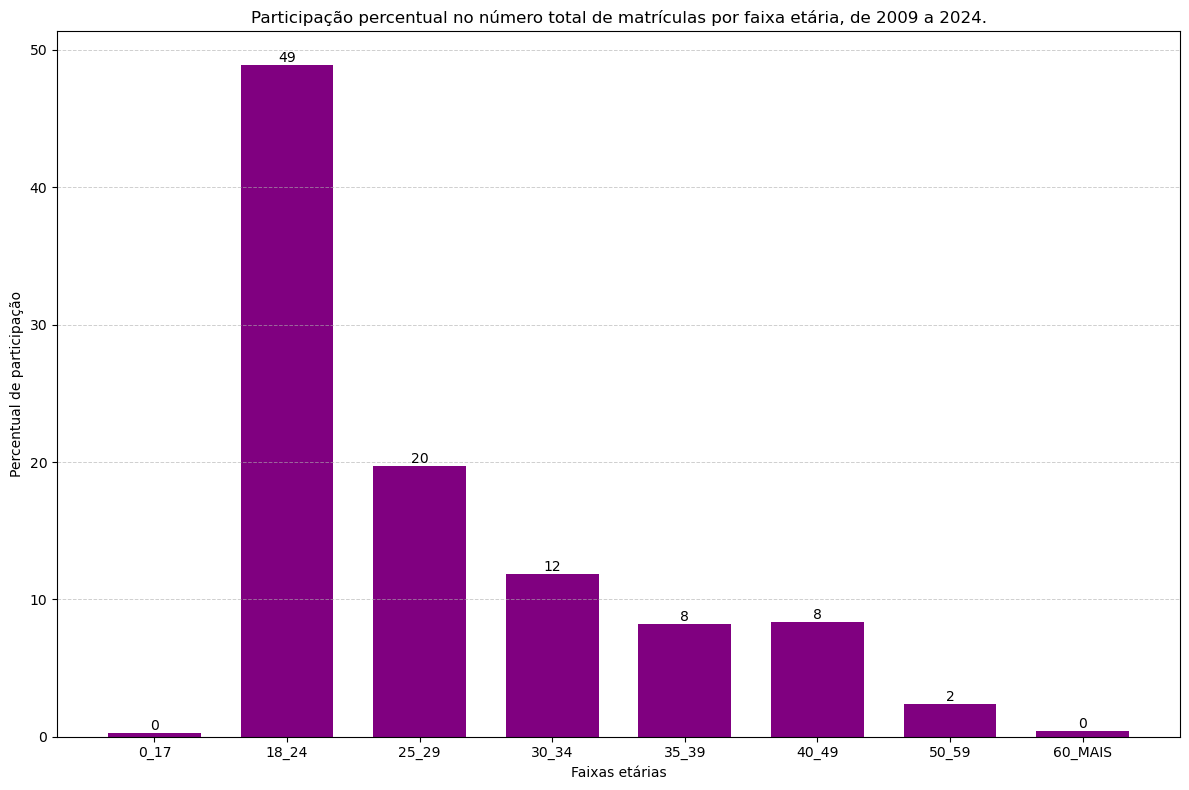

In [144]:
fig, ax = plt.subplots(figsize=(12, 8))

barras = plt.bar(
    faixas_etarias,
    percentuais,
    color='purple',
    width=0.7
)

plt.xlabel('Faixas etárias')
plt.ylabel('Percentual de participação')
plt.title('Participação percentual no número total de matrículas por faixa etária, de 2009 a 2024.')

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)

# Valores no topo das barras
for barra in barras:
    valor = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor,
        f'{valor:,.0f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()


# Salvar o gráfico em disco
fig.savefig(
    'part_%_matriculas_por_faixa_etaria.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

O gráfico acima mostra que os jovens de 18 a 29 representam aproximadamente 70% do total de matrículas no período considerado, sendo a faixa etária de 18 a 24 anos a que é mais participativa no total de matrículas, correspondendo a quase metade desse total.

> **Como evoluiu o número de matrículas de estudantes do sexo feminino e masculino entre 2009 e 2024?**
 

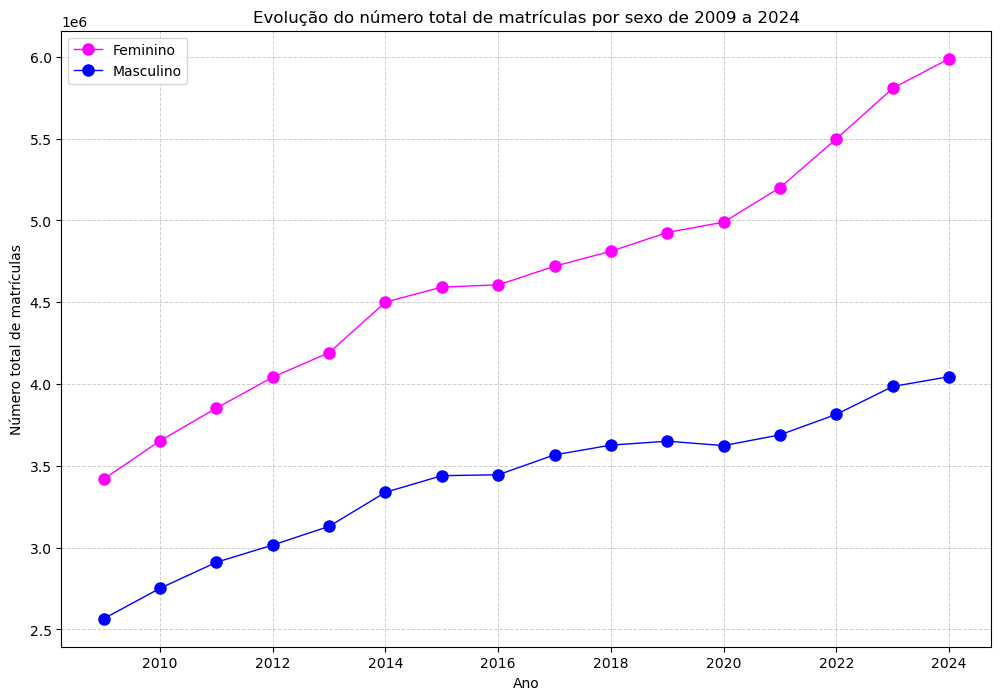

In [146]:
mat_fem = cursos.groupby('NU_ANO_CENSO')['QT_MAT_FEM'].sum()
mat_masc = cursos.groupby('NU_ANO_CENSO')['QT_MAT_MASC'].sum()


fig, ax = plt.subplots(figsize=(12, 8))

plt.plot(
    mat_fem.index,
    mat_fem.values,
    marker='o',
    markersize=8,
    color='magenta',
    lw=1,
    ls='-',
    label='Feminino'
)

plt.plot(
    mat_masc.index,
    mat_masc.values,
    marker='o',
    markersize=8,
    color='blue',
    lw=1,
    ls='-',
    label='Masculino'
)

plt.xlabel('Ano')
plt.ylabel('Número total de matrículas')
plt.title('Evolução do número total de matrículas por sexo de 2009 a 2024')

plt.grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)

# LEGENDA
plt.legend()

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_matriculas_por_sexo.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Vemos que a procura de mulheres pelo ensino superior foi significativamente maior que a procura masculina. Este fato é posto em evidência pelo gráfico acima, que mostra a evolução do total de matrículas por sexo. A participação feminina nesse total é, no mínimo, 1.33 vezes maior que a participação masculina.

In [147]:
round(mat_fem.min()/mat_masc.min(),2)

1.33

> **Como evoluiu o número de matrículas nos períodos diurno e noturno ao longo de 2009 a 2024?**


In [148]:
mat_dia = cursos.groupby('NU_ANO_CENSO')['QT_MAT_DIURNO'].sum()
mat_noite = cursos.groupby('NU_ANO_CENSO')['QT_MAT_NOTURNO'].sum()

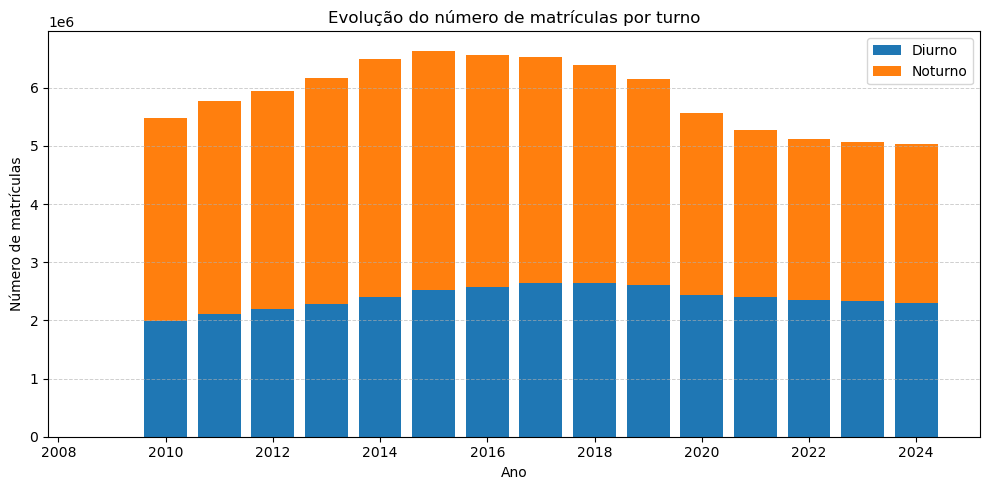

In [150]:
fig, ax = plt.subplots(figsize=(10, 5))

# Matrículas no período diurno
plt.bar(
    mat_dia.index,
    mat_dia.values,
    label='Diurno'
)

# Matrículas no período noturno
plt.bar(
    mat_noite.index,
    mat_noite.values,
    bottom=mat_dia.values,
    label='Noturno'
)

# ==========================================================================
# RÓTULOS
# ==========================================================================

plt.xlabel('Ano')
plt.ylabel('Número de matrículas')
plt.title('Evolução do número de matrículas por turno')

# ==========================================================================
# LEGENDA
# ==========================================================================

plt.legend()

# ==========================================================================
# GRADE
# ==========================================================================

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)

plt.tight_layout()

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_matriculas_por_turno.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

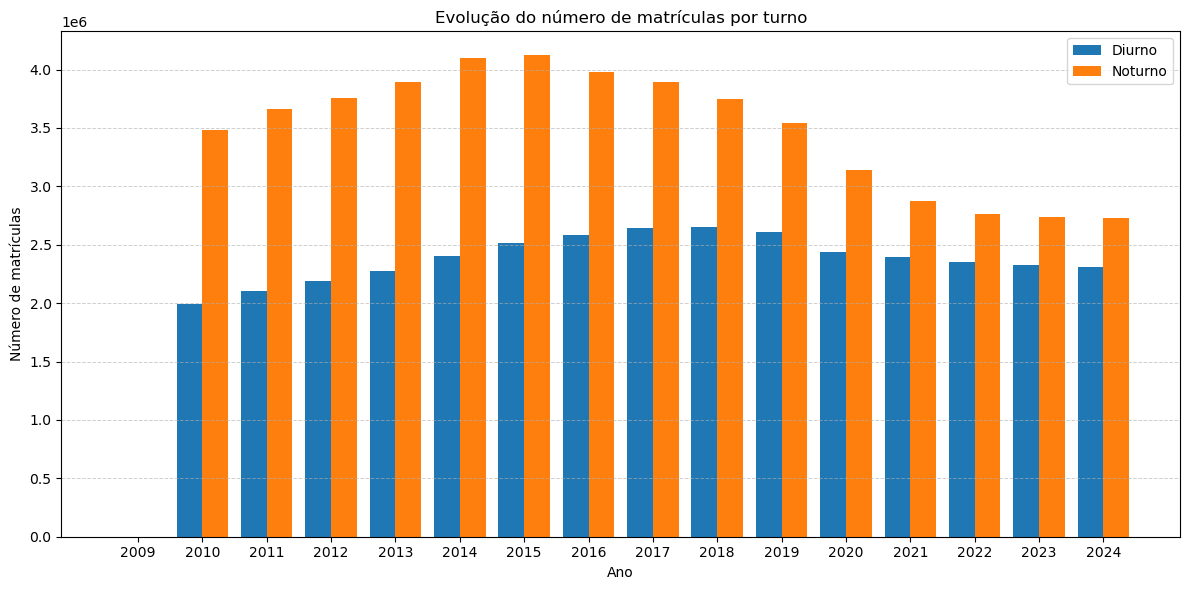

In [151]:
# Posições dos anos
x = np.arange(len(mat_dia.index))

# Largura das barras
largura = 0.4

plt.figure(figsize=(12, 6))

# Barras do período diurno
plt.bar(
    x - largura/2,
    mat_dia.values,
    width=largura,
    label='Diurno'
)

# Barras do período noturno
plt.bar(
    x + largura/2,
    mat_noite.values,
    width=largura,
    label='Noturno'
)

# ==========================================================================
# EIXO X
# ==========================================================================

plt.xticks(
    x,
    mat_dia.index
)

plt.xlabel('Ano')
plt.ylabel('Número de matrículas')
plt.title('Evolução do número de matrículas por turno')

# ==========================================================================
# LEGENDA
# ==========================================================================

plt.legend()

# ==========================================================================
# GRADE
# ==========================================================================

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)

plt.tight_layout()

plt.show()

Observa-se que a procura por cursos noturnos é significativamente maior que a procura por cursos diurnos. Uma possível explicação para esse fato é que, geralmente, quem procura por vagas noturnas exerce atividade remunerada durante o dia.

> **Como evoluiu o número de matrículas associadas a programas e formas de financiamento estudantil ao longo do período analisado?**


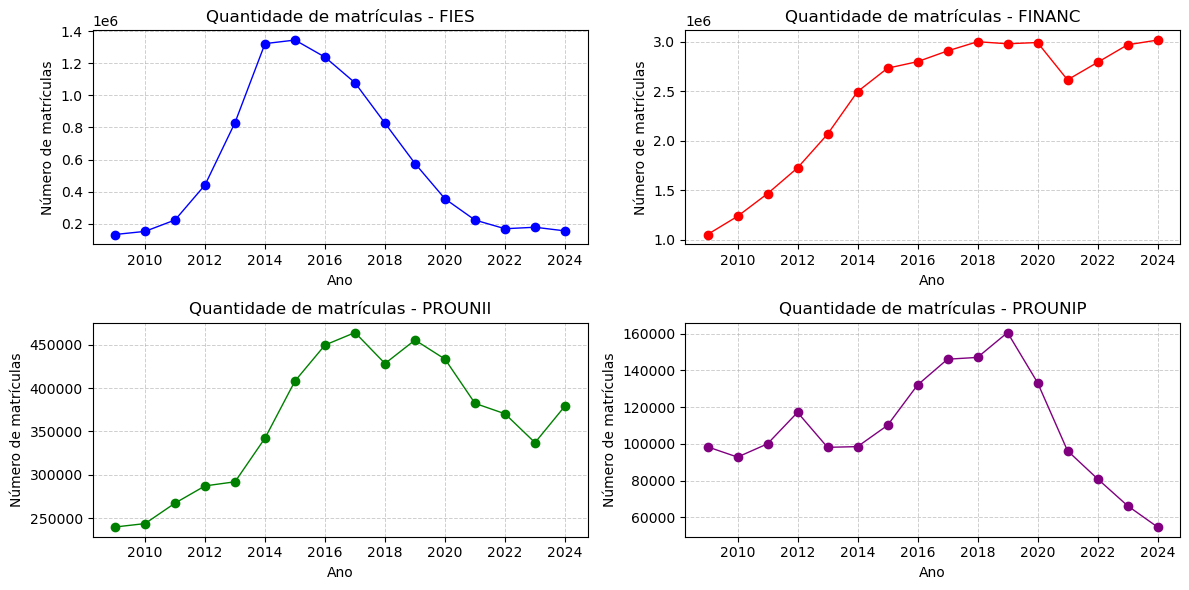

In [152]:
# ==========================================================================
# AGRUPAMENTO POR ANO
# ==========================================================================

mat_FIES = cursos.groupby('NU_ANO_CENSO')['QT_MAT_FIES'].sum()
mat_FINANC = cursos.groupby('NU_ANO_CENSO')['QT_MAT_FINANC'].sum()
mat_PROUNII = cursos.groupby('NU_ANO_CENSO')['QT_MAT_PROUNII'].sum()
mat_PROUNIP = cursos.groupby('NU_ANO_CENSO')['QT_MAT_PROUNIP'].sum()

# ==========================================================================
# CRIAÇÃO DOS SUBPLOTS
# ==========================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 6)
)


# ==========================================================================
# 1. 
# ==========================================================================

axes[0, 0].plot(
    mat_FIES.index,
    mat_FIES.values,
    marker='o',
    markersize=6,
    color='blue',
    lw=1,
    ls='-'
)

axes[0, 0].set_xlabel('Ano')
axes[0, 0].set_ylabel('Número de matrículas')
axes[0, 0].set_title('Quantidade de matrículas - FIES')

axes[0, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 2. 
# ==========================================================================

axes[0, 1].plot(
    mat_FINANC.index,
    mat_FINANC.values,
    marker='o',
    markersize=6,
    color='red',
    lw=1,
    ls='-'
)

axes[0, 1].set_xlabel('Ano')
axes[0, 1].set_ylabel('Número de matrículas')
axes[0, 1].set_title('Quantidade de matrículas - FINANC')

axes[0, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 3. 25 a 29 anos
# ==========================================================================

axes[1, 0].plot(
    mat_PROUNII.index,
    mat_PROUNII.values,
    marker='o',
    markersize=6,
    color='green',
    lw=1,
    ls='-'
)

axes[1, 0].set_xlabel('Ano')
axes[1, 0].set_ylabel('Número de matrículas')
axes[1, 0].set_title('Quantidade de matrículas - PROUNII')

axes[1, 0].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)


# ==========================================================================
# 4. 30 a 34 anos
# ==========================================================================

axes[1, 1].plot(
    mat_PROUNIP.index,
    mat_PROUNIP.values,
    marker='o',
    markersize=6,
    color='purple',
    lw=1,
    ls='-'
)

axes[1, 1].set_xlabel('Ano')
axes[1, 1].set_ylabel('Número de matrículas')
axes[1, 1].set_title('Quantidade de matrículas - PROUNIP')

axes[1, 1].grid(
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)




# ==========================================================================
# AJUSTE DO ESPAÇAMENTO
# ==========================================================================

plt.tight_layout()

plt.show()

Os gráficos evidenciam comportamentos distintos na evolução das matrículas nos programas de financiamento e bolsas analisados entre 2009 e 2024. O FIES apresentou forte crescimento até 2015, quando atingiu seu maior nível, seguido de uma queda acentuada nos anos posteriores. O FINANC mostrou trajetória de crescimento mais consistente, passando de aproximadamente 1 milhão de matrículas em 2009 para mais de 3 milhões em 2024, apesar de uma redução pontual em 2021. O PROUNI também apresentou crescimento expressivo até 2017, atingindo seu pico, seguido de oscilações e redução nos anos seguintes, embora tenha registrado recuperação em 2024. Já o PROUNIP apresentou comportamento mais oscilatório, com crescimento até 2019 e queda acentuada a partir de 2020, alcançando em 2024 seu menor nível da série. Em conjunto, os gráficos mostram que os programas tiveram trajetórias bastante distintas ao longo do período, com mudanças importantes tanto na expansão quanto na retração do número de matrículas.

### 3.5 Evolução dos concluintes


> **Como o número total de concluintes do ensino superior evoluiu no Brasil entre 2009 e 2024?**


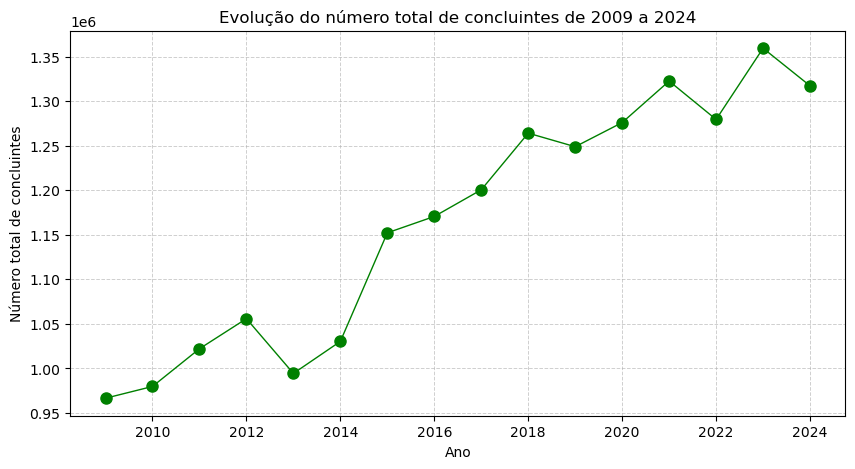

In [153]:
total_de_conc = cursos.groupby('NU_ANO_CENSO')['QT_CONC'].sum()


plt.figure(figsize=(10, 5))

plt.plot(
    total_de_conc.index,      # ANOS
    total_de_conc.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'green',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    
)

plt.xlabel('Ano')
plt.ylabel('Número total de concluintes')
plt.title('Evolução do número total de concluintes de 2009 a 2024')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)
plt.show()

> **Como o número de concluintes evoluiu nas diferentes regiões brasileiras entre 2009 e 2024?**


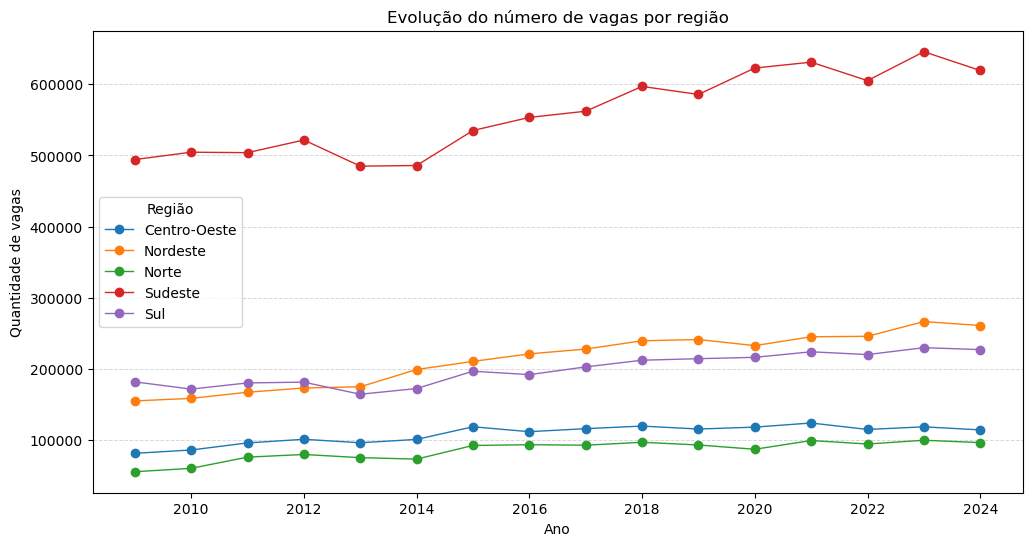

In [155]:
total_de_conc = cursos.groupby(['NU_ANO_CENSO','NO_REGIAO'])['QT_CONC'].sum().unstack()


fig, ax = plt.subplots(figsize=(12, 6))

total_de_conc.plot(
    ax=ax,
    marker='o',
    linewidth=1
)

ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de vagas')
ax.set_title('Evolução do número de vagas por região')

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

ax.legend(title='Região')

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_vagas_por_regiao.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

> **Como se comportou a evolução do número de concluintes entre instituições públicas e privadas no período de 2009 a 2024?**


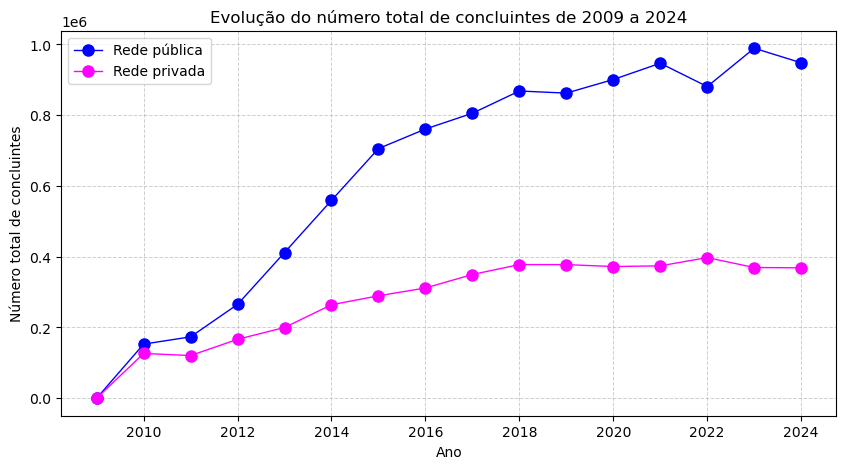

In [157]:
total_de_conc_pub = cursos.groupby('NU_ANO_CENSO')['QT_CONC_PROCESCPUBLICA'].sum()
total_de_conc_priv = cursos.groupby('NU_ANO_CENSO')['QT_CONC_PROCESCPRIVADA'].sum()


fig, ax = plt.subplots(figsize=(10, 5))

plt.plot(
    total_de_conc_pub.index,      # ANOS
    total_de_conc_pub.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede pública'
)

plt.plot(
    total_de_conc_priv.index,      # ANOS
    total_de_conc_priv.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede privada'
)



plt.xlabel('Ano')
plt.ylabel('Número total de concluintes')
plt.title('Evolução do número total de concluintes de 2009 a 2024')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_concluintes.png',
    dpi=300,
    bbox_inches='tight'
)


plt.show()

O gráfico acima mostra que a quantidade de concluintes no período considerado tem tendência geral crescente, com o número de concluintes da rede pública apresentando um crescimento acelerado a partir de 2011, enquanto que a quantidade de concluintes da rede privada apresentou crescimento mais lento e con tendência de estabilidade próximo de 400.000. A quantidade total de concluintes oriundos da rede pública no período considerado é cerca de 2.3 vezes maior que a quantidade total de concluintes oriundos da rede privada.

In [158]:
round(total_de_conc_pub.values.sum()/total_de_conc_priv.values.sum(),2)

2.29

Uma possível explicação para isso é o fato de que a quantidade de matrículas de alunos oriundos da rede pública é superior ao número de alunos matriculados que têm origem na rede privada.

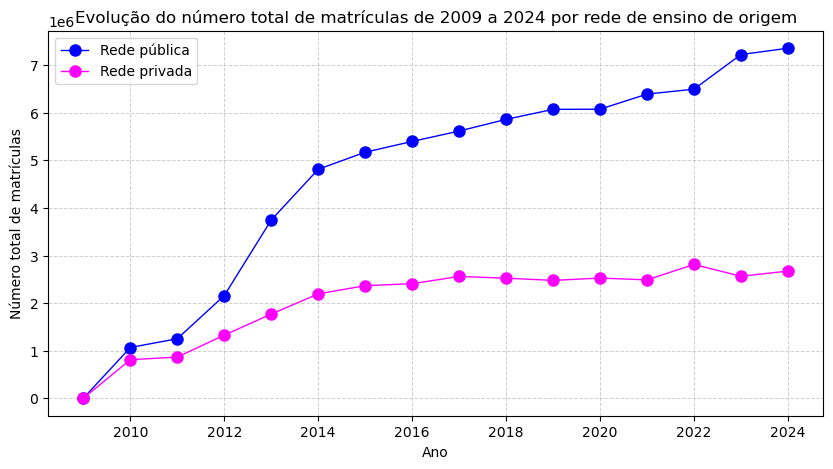

In [160]:
total_de_mat_pub = cursos.groupby('NU_ANO_CENSO')['QT_MAT_PROCESCPUBLICA'].sum()
total_de_mat_priv = cursos.groupby('NU_ANO_CENSO')['QT_MAT_PROCESCPRIVADA'].sum()


fig, ax = plt.subplots(figsize=(10, 5))

plt.plot(
    total_de_mat_pub.index,      # ANOS
    total_de_mat_pub.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede pública'
)

plt.plot(
    total_de_mat_priv.index,      # ANOS
    total_de_mat_priv.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede privada'
)



plt.xlabel('Ano')
plt.ylabel('Número total de matrículas')
plt.title('Evolução do número total de matrículas de 2009 a 2024 por rede de ensino de origem')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_matriculas_por_rede_ensino.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

> **Como evoluiu o número de concluintes segunda modalidade de ensino, comparando cursos presenciais e cursos a distância (EAD), entre 2009 e 2024?**

De 2009 a 2024, observa-se uma tendência geral de crescimento do número de concluintes de cursos EAD ao passo que, a partir de 2018, a quantidade de concluintes de cursos presenciais vem apresentando tendência geral de queda. O comportanmento dessas quantidades com o tempo faz com que a discrepância entre as quantidades de concluintes dos cursos presenciais e dos cursos EAD torne-se menor com o passar do tempo.

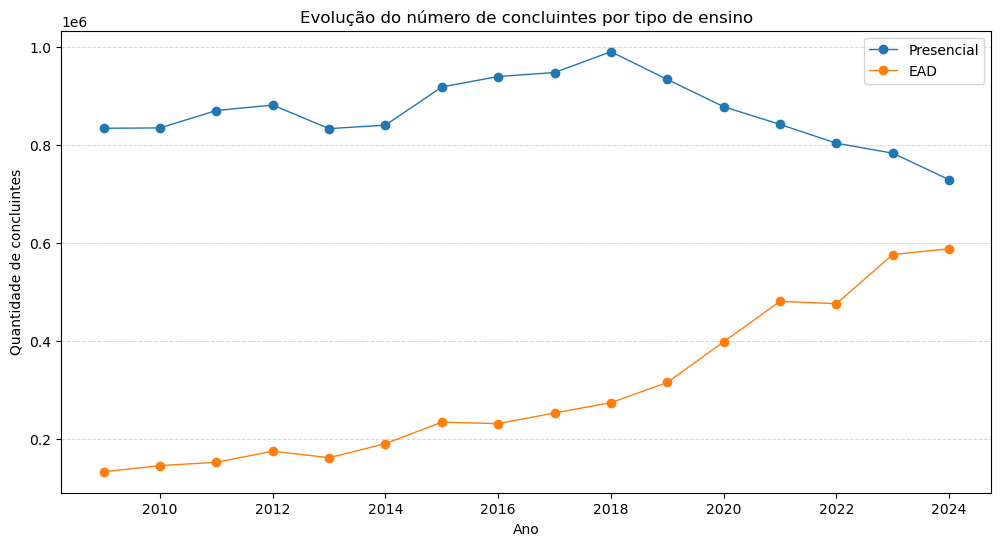

In [162]:
total_de_conc_mod_ens = cursos.groupby(['NU_ANO_CENSO','TP_MODALIDADE_ENSINO'])['QT_CONC'].sum().unstack()

total_de_conc_mod_ens = total_de_conc_mod_ens.rename(
    columns={
        1: 'Presencial',
        2: 'EAD'
    }
)

fig, ax = plt.subplots(figsize=(12, 6))

total_de_conc_mod_ens.plot(
    ax=ax,
    marker='o',
    linewidth=1
)

ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de concluintes')
ax.set_title('Evolução do número de concluintes por tipo de ensino')

ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.5
)

ax.legend()

# Salvar o gráfico em disco
fig.savefig(
    'evolucao_concluintes_por_tipo_ensino.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 3.6 Diferenças entre instituições públicas e privadas


> **Como evoluiu a taxa de crescimento das matrículas nas instituições públicas e privadas?**


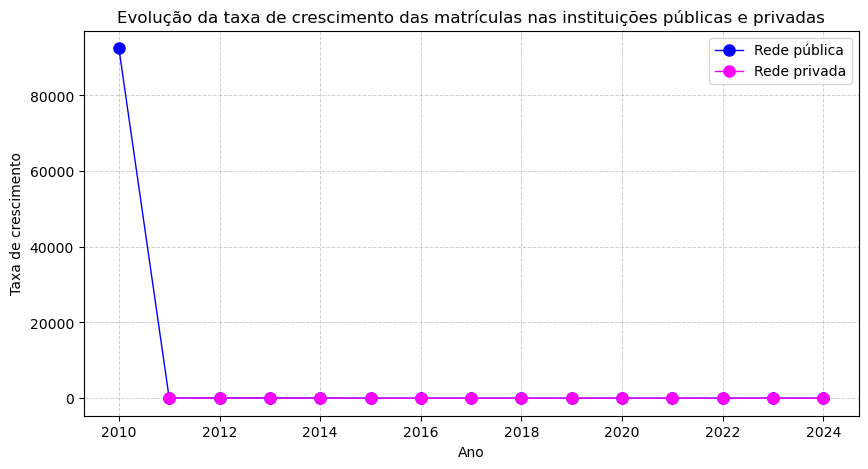

In [163]:
taxa_de_cresc_pub = cursos.groupby('NU_ANO_CENSO')['QT_MAT_PROCESCPUBLICA'].sum().pct_change()*100
taxa_de_cresc_priv = cursos.groupby('NU_ANO_CENSO')['QT_MAT_PROCESCPRIVADA'].sum().pct_change()*100


plt.figure(figsize=(10, 5))

plt.plot(
    taxa_de_cresc_pub.index,      # ANOS
    taxa_de_cresc_pub.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede pública'
)

plt.plot(
    taxa_de_cresc_priv.index,      # ANOS
    taxa_de_cresc_priv.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede privada'
)



plt.xlabel('Ano')
plt.ylabel('Taxa de crescimento')
plt.title('Evolução da taxa de crescimento das matrículas nas instituições públicas e privadas')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

plt.show()

Podemos observar que as taxas de crescimento das matrículas nas redes pública e privada foram elevadas no início do período, especialmente entre 2011 e 2013. A partir de 2014, observa-se uma desaceleração acentuada do crescimento, com as taxas se aproximando de valores próximos de zero a partir de 2016. Nos anos seguintes, ambas as redes apresentam oscilações, sendo estas mais pronunciadas na rede privada, especialmente entre 2021 e 2024.

> **Como evoluiu a relação $R_t=\displaystyle\frac{C_t}{I_t}$ entre o número de ingressantes e concluintes nas instituições públicas e privadas?**


Observe que a variável `TP_CATEGORIA_ADMINISTRATIVA` tem nove categorias.

1. Pública Federal
2. Pública Estadual
3. Pública Municipal
4. Privada com fins lucrativos
5. Privada sem fins lucrativos
6. Privada - Particular em sentido estrito
7. Especial
8. Privada comunitária
9. Privada confessional

Com exceção da categoria 7, vamos construir a variável `TIPO_IES` que mapeia cada categoria em Pública ou Privada.

In [164]:
cursos['TIPO_IES'] = cursos['TP_CATEGORIA_ADMINISTRATIVA'].map({
    1: 'Pública',
    2: 'Pública',
    3: 'Pública',
    4: 'Privada',
    5: 'Privada',
    6: 'Privada',
    8: 'Privada',
    9: 'Privada'
})

In [165]:
df_2 = cursos['TIPO_IES']

In [166]:
df_2.value_counts()

TIPO_IES
Privada    2423615
Pública     227736
Name: count, dtype: int64

In [167]:
ing_inst_pub = cursos[cursos['TIPO_IES'] == 'Pública'].groupby('NU_ANO_CENSO')['QT_ING'].sum()
ing_inst_priv = cursos[cursos['TIPO_IES'] == 'Privada'].groupby('NU_ANO_CENSO')['QT_ING'].sum()

In [168]:
conc_inst_pub = cursos[cursos['TIPO_IES'] == 'Pública'].groupby('NU_ANO_CENSO')['QT_CONC'].sum()
conc_inst_priv = cursos[cursos['TIPO_IES'] == 'Privada'].groupby('NU_ANO_CENSO')['QT_CONC'].sum()

In [169]:
rel_C_I_pub = conc_inst_pub/ing_inst_pub
rel_C_I_priv = conc_inst_priv/ing_inst_priv

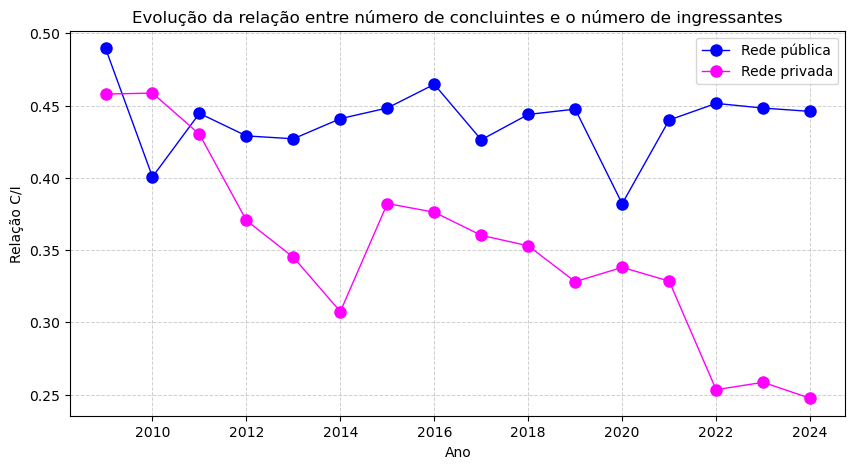

In [170]:
plt.figure(figsize=(10, 5))

plt.plot(
    rel_C_I_pub.index,      # ANOS
    rel_C_I_pub.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede pública'
)

plt.plot(
    rel_C_I_priv.index,      # ANOS
    rel_C_I_priv.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Rede privada'
)

plt.xlabel('Ano')
plt.ylabel('Relação C/I')
plt.title('Evolução da relação entre número de concluintes e o número de ingressantes')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

plt.show()

A razão anual entre concluintes e ingressantes apresentou maior estabilidade na rede pública, enquanto na rede privada houve uma redução mais pronunciada ao longo de 2009–2024, ampliando a diferença observada entre as duas redes.

> **Existem diferenças na evolução das matrículas entre instituições públicas e privadas segundo a modalidade de ensino (presencial e EAD)?**


In [171]:
mat_pub_pres = (
    cursos[
        (cursos['TP_MODALIDADE_ENSINO'] == 1) &
        (cursos['TIPO_IES'] == 'Pública')
    ]
    .groupby('NU_ANO_CENSO')['QT_MAT']
    .sum()
)


mat_pub_ead = (
    cursos[
        (cursos['TP_MODALIDADE_ENSINO'] == 2) &
        (cursos['TIPO_IES'] == 'Pública')
    ]
    .groupby('NU_ANO_CENSO')['QT_MAT']
    .sum()
)

In [172]:
mat_priv_pres = (
    cursos[
        (cursos['TP_MODALIDADE_ENSINO'] == 1) &
        (cursos['TIPO_IES'] == 'Privada')
    ]
    .groupby('NU_ANO_CENSO')['QT_MAT']
    .sum()
)


mat_priv_ead = (
    cursos[
        (cursos['TP_MODALIDADE_ENSINO'] == 2) &
        (cursos['TIPO_IES'] == 'Privada')
    ]
    .groupby('NU_ANO_CENSO')['QT_MAT']
    .sum()
)

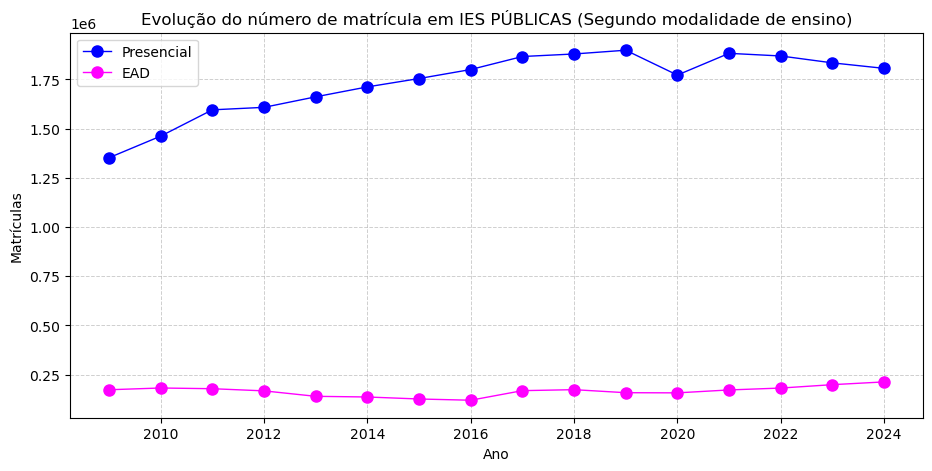

In [173]:
plt.figure(figsize=(11, 5))

plt.plot(
    mat_pub_pres.index,      # ANOS
    mat_pub_pres.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Presencial'
)

plt.plot(
    mat_pub_ead.index,      # ANOS
    mat_pub_ead.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='EAD'
)

plt.xlabel('Ano')
plt.ylabel('Matrículas')
plt.title('Evolução do número de matrícula em IES PÚBLICAS (Segundo modalidade de ensino)')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

plt.show()

Nas universidade públicas, a modalidade de ensino EAD, embora esteja presente, detém uma quantidade de matrículas significativamente inferior em relação ao número de matrículas em vagas presenciais. O total acumulado de matrículas em ensino presencial é aproximadamente 10.5 vezes maior que a quantidade total acumulada de matrículas em cursos EAD nas nuniversidades públicas.

In [174]:
round(mat_pub_pres.values.sum()/mat_pub_ead.values.sum(),2)

10.5

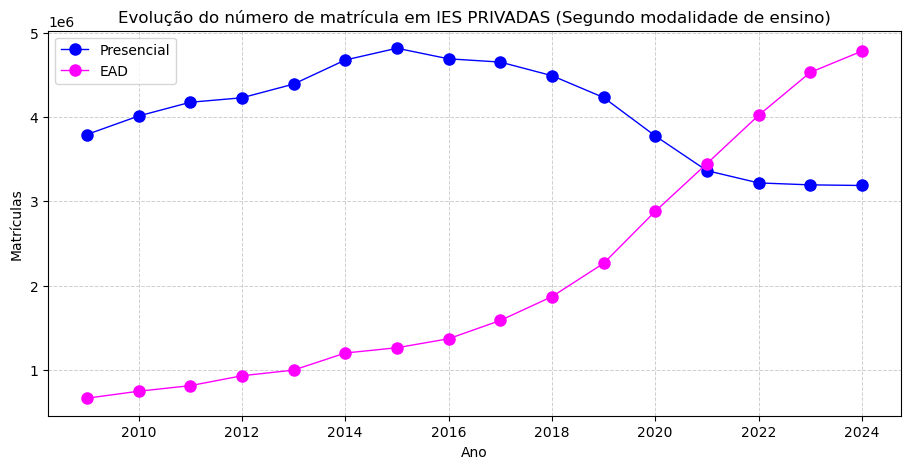

In [175]:
plt.figure(figsize=(11, 5))

plt.plot(
    mat_priv_pres.index,      # ANOS
    mat_priv_pres.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='Presencial'
)

plt.plot(
    mat_priv_ead.index,      # ANOS
    mat_priv_ead.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='EAD'
)

plt.xlabel('Ano')
plt.ylabel('Matrículas')
plt.title('Evolução do número de matrícula em IES PRIVADAS (Segundo modalidade de ensino)')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

plt.show()

Nas instituições privadas, a quantidade de matrículas em cursos presenciais entrou em queda a partir de 2015, ao passo que o número de matrículas em cursos EAD tem crescido desde 2009, sendo esse crescimento acelerado a partir de 2018. A partir de 2021, a quantidade de matrículas na modalidade EAD superou as matrículas presenciais, mantendo uma tendência crescente.

> **Como evoluiu a participação das instituições públicas e privadas na oferta de cursos EAD?**


In [ ]:
cursos[['NU_ANO_CENSO','TP_MODALIDADE_ENSINO','TIPO_IES','QT_CURSO']]

In [ ]:
cursos[cursos['TP_MODALIDADE_ENSINO'] == 2].groupby(['NU_ANO_CENSO','TIPO_IES'])['QT_CURSO'].sum()

In [ ]:
quant_total_cursos_ead = cursos[cursos['TP_MODALIDADE_ENSINO'] == 2].groupby('NU_ANO_CENSO')['QT_CURSO'].sum()

In [ ]:
quant_total_cursos_ead_pub = (
    cursos[(cursos['TP_MODALIDADE_ENSINO'] == 2) 
    & (cursos['TIPO_IES'] == 'Pública')].groupby('NU_ANO_CENSO')['QT_CURSO'].sum()
)

In [ ]:
quant_total_cursos_ead_priv = (
    cursos[(cursos['TP_MODALIDADE_ENSINO'] == 2) 
    & (cursos['TIPO_IES'] == 'Privada')].groupby('NU_ANO_CENSO')['QT_CURSO'].sum()
)

In [ ]:
participacao_pub = quant_total_cursos_ead_pub/quant_total_cursos_ead*100

In [ ]:
participacao_priv = quant_total_cursos_ead_priv/quant_total_cursos_ead*100

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    participacao_pub.index,      # ANOS
    participacao_pub.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'blue',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='IES Públicas'
)

plt.plot(
    participacao_priv.index,      # ANOS
    participacao_priv.values,     # VALORES DE CADA ANO
    marker='o',                      # OUTRAS OPÇÕES: 's','^','D','*','x','+'
    markersize = 8,                  # TAMANHO DO MARCADOR
    color = 'magenta',               # COR DA LINHA
    lw = 1,                          # ESPESSURA DA LINHA 
    ls = '-',                        # ESTILO DA LINHA
    label='IES Privadas'
)

plt.xlabel('Ano')
plt.ylabel('%')
plt.title('Evolução da participação (%) das IES públicas e privadas na oferta de cursos EAD')

plt.grid(
    linestyle = '--',
    linewidth = 0.7,
    alpha = 0.6
)

plt.legend()

plt.show()

Entre 2009 e 2024, observa-se uma redução contínua da participação das instituições públicas na oferta de cursos EAD, acompanhada por um aumento da participação das instituições privadas. Em 2009, as instituições públicas representavam aproximadamente 47% da oferta, enquanto as privadas representavam cerca de 53%. Em 2024, essas participações passaram para aproximadamente 6% e 94%, respectivamente. A partir de aproximadamente 2018, a participação privada ultrapassa 80% e permanece próxima de 90% nos anos finais do período.

## 4. Relatório 

### 4.1 Introdução

Este projeto teve como objetivo analisar a evolução do ensino superior brasileiro entre 2009 e 2024, utilizando dados do Censo da Educação Superior. A pergunta de negócio que orientou a análise foi:

> **Como a oferta e a demanda por ensino superior no Brasil evoluíram entre 2009 e 2024, e quais segmentos apresentaram as maiores mudanças?**

A partir dessa questão, foram investigadas diferentes dimensões do ensino superior, incluindo o número de cursos, vagas ofertadas, ingressantes, matrículas e concluintes, além de diferenças relacionadas às regiões brasileiras, instituições públicas e privadas e modalidades de ensino.

A análise foi realizada utilizando principalmente as variáveis quantitativas do Censo e operações de agrupamento e agregação com `pandas`, complementadas por indicadores de participação, crescimento e relações entre variáveis.

---

### 4.2 Preparação e tratamento dos dados

Inicialmente, foram reunidos os dados do Cadastro de Cursos do Censo da Educação Superior referentes ao período de 2009 a 2024.

Foram realizadas etapas de preparação dos dados, incluindo:

- seleção das variáveis relevantes para o projeto;
- organização dos datasets anuais;
- padronização das informações;
- verificação dos tipos das variáveis;
- análise de valores ausentes;
- verificação de registros duplicados;
- verificação da consistência temporal;
- análise das categorias das variáveis qualitativas;
- investigação de valores extremos;
- verificação da consistência dos totais.

Após o processamento, os dados foram organizados de modo a permitir análises temporais, regionais e institucionais.

---



### 4.3 Evolução dos ingressantes

A análise mostrou uma tendência geral de crescimento do número de ingressantes no ensino superior brasileiro ao longo do período analisado.

O número de ingressantes passou de aproximadamente **2,08 milhões em 2009** para aproximadamente **4,86 milhões em 2024**. Apesar da tendência geral de crescimento, ocorreram algumas reduções pontuais, especialmente entre 2012 e 2013 e entre 2014 e 2015. O maior crescimento anual ocorreu entre 2021 e 2022.

Também foram observadas diferenças importantes entre as regiões brasileiras. No acumulado de 2009 a 2024, o **Sudeste apresentou a maior quantidade de ingressantes**, enquanto o **Norte apresentou a menor**. Entre os estados, São Paulo apresentou a maior quantidade de ingressantes no período.

De modo geral, as diferentes regiões apresentaram tendência de crescimento no número de ingressantes, embora em magnitudes distintas.

---

### 4.4 Evolução do número de cursos

O número de cursos de ensino superior apresentou uma tendência geral de crescimento entre 2009 e 2024.

A maior expansão anual ocorreu em **2018**, quando o número de cursos aumentou aproximadamente **6,82%** em relação a 2017, correspondendo a aproximadamente 2.380 cursos adicionais.

Após 2018, observou-se uma desaceleração do crescimento. Em 2023, a variação anual foi praticamente nula, enquanto em 2024 ocorreu uma redução aproximada de **1,01%** em relação ao ano anterior.

A análise regional mostrou que o Sudeste apresentou as maiores quantidades de cursos durante o período, enquanto as regiões Norte e Centro-Oeste apresentaram quantidades relativamente mais estáveis. A região Sul apresentou uma leve tendência de redução a partir de 2019.

---



### 4.5 Evolução das vagas ofertadas

O número de vagas ofertadas apresentou, de maneira geral, forte expansão ao longo do período.

Foram observadas taxas de crescimento especialmente elevadas entre 2013 e 2016 e novamente entre 2018 e 2021. Em contrapartida, ocorreram reduções em 2011 e 2024.

Um aspecto importante identificado na análise foi a diferença entre a evolução da quantidade de vagas e sua taxa de ocupação.

A quantidade total de vagas aumentou significativamente, passando de aproximadamente **4,75 milhões em 2009** para mais de **23,66 milhões em 2024**. Entretanto, a taxa de ocupação das vagas apresentou tendência geral de redução.

A taxa de ocupação atingiu aproximadamente **59% em 2012**, mas caiu para aproximadamente **17,4% em 2021**, apresentando posteriormente uma pequena recuperação e chegando a aproximadamente **21,2% em 2024**.

Esse resultado mostra que a expansão da oferta de vagas não foi acompanhada, na mesma proporção, pelo crescimento da ocupação dessas vagas.

---

### 4.6 Evolução das matrículas

O número total de matrículas apresentou crescimento ao longo do período analisado.

Em 2009 foram registradas aproximadamente **5,99 milhões de matrículas**, enquanto em 2024 esse número chegou a aproximadamente **10,23 milhões**.

A análise da distribuição etária mostrou predominância das faixas mais jovens. Os estudantes de **18 a 29 anos representaram aproximadamente 70% das matrículas** no período, sendo a faixa de 18 a 24 anos a mais representativa, correspondendo a aproximadamente metade das matrículas analisadas.

Também foi observada uma participação feminina superior à masculina. A quantidade de matrículas de mulheres foi significativamente maior durante o período analisado.

Quanto ao turno, as matrículas em cursos **noturnos** apresentaram quantidade superior às matrículas em cursos diurnos.

---

### 4.7 Matrículas associadas a programas de financiamento e bolsas

A análise das matrículas associadas a programas de financiamento e bolsas revelou comportamentos distintos entre os programas analisados.

O **FIES** apresentou forte crescimento até 2015, seguido de redução nos anos posteriores.

O **FINANC** apresentou uma trajetória de crescimento mais consistente, passando de aproximadamente 1 milhão de matrículas em 2009 para mais de 3 milhões em 2024, apesar de uma redução pontual em 2021.

O **PROUNI** apresentou crescimento expressivo até 2017, seguido por oscilações e redução nos anos seguintes, com recuperação em 2024.

O **PROUNIP** apresentou comportamento mais oscilatório, com crescimento até 2019 e redução acentuada a partir de 2020.

Esses resultados evidenciam que os diferentes mecanismos de financiamento e bolsas apresentaram trajetórias distintas ao longo do período.

---



### 4.8 Evolução dos concluintes

A análise dos concluintes mostrou uma tendência geral de crescimento ao longo do período analisado.

Também foram observadas diferenças entre as modalidades de ensino. O número de concluintes em cursos **EAD apresentou tendência geral de crescimento**, enquanto o número de concluintes em cursos presenciais apresentou tendência de redução a partir de aproximadamente 2018.

Consequentemente, a diferença entre o número de concluintes das duas modalidades diminuiu ao longo do tempo.

---

### 4.9 Diferenças entre instituições públicas e privadas

A análise das matrículas nas instituições públicas e privadas mostrou taxas de crescimento mais elevadas no início do período, especialmente entre 2011 e 2013.

A partir de aproximadamente 2014, ocorreu uma desaceleração do crescimento, com as taxas se aproximando de valores menores a partir de 2016. Nos anos seguintes, foram observadas oscilações, especialmente na rede privada.

Também foi analisada a razão anual entre concluintes e ingressantes:

$$
R_t =
\frac{C_t}{I_t},
$$

em que \(C_t\) representa o número de concluintes e \(I_t\) o número de ingressantes no ano \(t\).

Essa razão apresentou maior estabilidade na rede pública, enquanto na rede privada ocorreu uma redução mais pronunciada ao longo do período de 2009 a 2024.

É importante destacar que essa razão representa uma comparação entre dois fluxos anuais. Portanto, ela não deve ser interpretada como uma taxa de conclusão dos ingressantes daquele mesmo ano, uma vez que ingressantes e concluintes pertencem, em geral, a coortes diferentes.

---

### 4.10 Diferenças entre ensino presencial e EAD

A análise das matrículas segundo modalidade de ensino revelou mudanças importantes na composição do ensino superior brasileiro.

Nas instituições públicas, as matrículas em cursos presenciais permaneceram muito superiores às matrículas em EAD durante o período analisado.

Nas instituições privadas, por outro lado, observou-se uma redução das matrículas presenciais a partir de aproximadamente 2015, enquanto as matrículas em EAD apresentaram crescimento contínuo desde 2009, com aceleração a partir de aproximadamente 2018.

A partir de 2021, o número de matrículas EAD nas instituições privadas passou a superar o número de matrículas presenciais.

Também foi analisada a participação das instituições públicas e privadas na oferta de cursos EAD. Em 2009, as instituições públicas representavam aproximadamente **47%** da oferta analisada, enquanto as privadas representavam aproximadamente **53%**. Em 2024, essas participações passaram para aproximadamente **6%** e **94%**, respectivamente.

Portanto, ao longo do período analisado, observou-se uma mudança significativa na composição da oferta de cursos EAD, com aumento da participação das instituições privadas e redução da participação das instituições públicas.

---



### 4.11 Distribuição regional

A análise regional mostrou uma forte concentração da oferta e da demanda por ensino superior na região Sudeste.

Considerando o total de vagas ofertadas no período, aproximadamente **79,9%** estavam concentradas na região Sudeste, enquanto a região Norte representava aproximadamente **2,9%**.

Entre os estados, São Paulo apresentou aproximadamente **27,0% do total de ingressantes** no período analisado, seguido por Minas Gerais e Rio de Janeiro.

Esses resultados mostram que a distribuição do ensino superior brasileiro apresenta forte concentração espacial, especialmente na região Sudeste.

---

### 4.12 Principais resultados

De maneira geral, a análise realizada permite destacar os seguintes resultados:

1. **Expansão da demanda:** o número de ingressantes apresentou crescimento expressivo entre 2009 e 2024.

2. **Expansão da oferta de cursos:** o número de cursos apresentou tendência geral de crescimento, embora com desaceleração nos anos finais do período.

3. **Expansão das vagas:** houve forte crescimento do número de vagas ofertadas, especialmente entre 2013 e 2021.

4. **Redução da ocupação relativa:** apesar da expansão das vagas, a taxa de ocupação apresentou tendência geral de queda entre 2012 e 2021, com recuperação moderada posteriormente.

5. **Crescimento das matrículas:** o número de matrículas aumentou de aproximadamente 5,99 milhões em 2009 para aproximadamente 10,23 milhões em 2024.

6. **Predominância de estudantes jovens:** a faixa etária de 18 a 24 anos apresentou a maior participação nas matrículas.

7. **Maior participação feminina:** as mulheres apresentaram quantidade de matrículas superior à dos homens durante o período analisado.

8. **Mudanças nos mecanismos de financiamento:** FIES, FINANC e PROUNI apresentaram trajetórias distintas ao longo do período.

9. **Expansão do EAD:** o ensino a distância apresentou forte expansão, especialmente nas instituições privadas.

10. **Mudança na composição do EAD:** a participação das instituições privadas na oferta de cursos EAD aumentou significativamente, enquanto a participação das instituições públicas diminuiu.

11. **Concentração regional:** o Sudeste apresentou participação muito superior às demais regiões na oferta de vagas e no número de ingressantes.

---



### 4.13 Considerações finais

A análise exploratória dos dados do Censo da Educação Superior entre 2009 e 2024 permitiu identificar importantes transformações na estrutura do ensino superior brasileiro.

O período foi marcado por expansão do número de ingressantes, matrículas, cursos e vagas, mas esses indicadores não apresentaram necessariamente o mesmo comportamento. Um dos resultados mais relevantes foi a expansão expressiva da oferta de vagas acompanhada por uma redução da taxa de ocupação, indicando que o crescimento da capacidade de oferta não ocorreu na mesma proporção que o preenchimento dessas vagas.

Outra transformação importante foi o crescimento do ensino a distância, especialmente entre as instituições privadas. A partir dos últimos anos analisados, o EAD passou a representar uma parcela cada vez mais significativa das matrículas e da oferta de cursos nesse segmento.

Também foram identificadas diferenças importantes entre regiões, estados, instituições públicas e privadas e características dos estudantes. A região Sudeste apresentou forte concentração da oferta e da demanda, enquanto as demais regiões apresentaram volumes menores e padrões de crescimento distintos.

De forma geral, os resultados mostram que o ensino superior brasileiro passou por uma importante transformação entre 2009 e 2024, caracterizada simultaneamente pela expansão quantitativa do sistema e por mudanças em sua composição, especialmente relacionadas à modalidade EAD, à participação das instituições privadas e à distribuição regional.

O projeto também permitiu aplicar diferentes etapas de um processo de Ciência de Dados, incluindo preparação e limpeza dos dados, exploração, agrupamento, agregação, criação de indicadores, análise de séries temporais e visualização dos resultados.

Como possibilidades de continuidade, as análises realizadas podem servir de base para projetos mais avançados envolvendo modelagem preditiva, análise espacial, séries temporais e técnicas de Machine Learning aplicadas aos dados da educação superior.

## Versões dos pacotes usados

In [ ]:
%reload_ext watermark
%watermark -a "Mauricio Vinhote" 

In [ ]:
%watermark -v -m

In [ ]:
%watermark --iversions

# Fim!